# EDAB 6808: Assignment 5: Retrieval-Augmented Generation (RAG)
Group Members: `Reatile Seekoei` `Fumane Malangabe` `Mamelo Malape`


**Learner Guide chatbot.** PyMuPDF text + rebuilt tables → heading-aware chunks → `bge-small` embeddings → Qdrant (persisted on Drive) → BM25 + dense **RRF** → **cross-encoder rerank** with sub-question coverage → Qwen2.5-3B-Instruct, **LoRA fine-tuned** on the guide → citations built from chunk metadata → Gradio.

**Before you start**
1. `Runtime → Change runtime type → T4 GPU`.
2. Put the **EDAB 6808 Learner Guide PDF** in `MyDrive/EDAB6808/` (or upload it to `/content`) and check `PDF_NAME` in section 1.
3. Run **Section 0** first. If you have already imported packages in this session, use `Runtime → Restart session` after installation, then run from Section 1 onwards. For a fresh session you can continue normally. Everything that must survive a runtime reset (Qdrant store, LoRA adapter, training data, evaluation results, report tables) is written to `MyDrive/EDAB6808/rag_store/`.

## 0. Install
Run this cell before importing the models or Gradio. The `torchao` installation belongs
here because Section 7 can load an existing LoRA adapter before Section 7b starts.
If packages were already imported in this runtime, restart the session after this cell,
then continue from Section 1. Keep a T4 GPU selected.


In [ ]:
%pip install -q --upgrade pymupdf sentence-transformers qdrant-client rank_bm25 "gradio>=5.50,<7" transformers accelerate peft "torchao>=0.16.0" pandas rapidfuzz openpyxl matplotlib
print("Installation finished. If packages were already imported, restart the session, then continue from Section 1.")


Installation finished. If packages were already imported, restart the session, then continue from Section 1.


## 1. Configuration

In [ ]:
import os, re, time, json, uuid, hashlib, collections, shutil, random
import numpy as np, pandas as pd, torch

# ---- EDIT THESE ----------------------------------------------------------
USE_DRIVE = True                              # persist Qdrant store, LoRA adapter and results on Google Drive
DRIVE_DIR = "/content/drive/MyDrive/EDAB6808"
PDF_NAME  = "Study_Guide.pdf"                  # <-- Changed from "/content/Study_Guide.pdf" to prevent path corruption
SEED      = 42
# --------------------------------------------------------------------------

assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > T4 GPU, then rerun."
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

# optional Hugging Face token (Colab: key icon > Secrets > HF_TOKEN) to remove the rate-limit warning
try:
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    print("HF token loaded from Colab Secrets.")
except Exception:
    print("No HF_TOKEN secret found: continuing with anonymous downloads.")

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = f"{DRIVE_DIR}/rag_store"
else:
    WORK_DIR = "/content/rag_store"
os.makedirs(WORK_DIR, exist_ok=True)

pdf_candidates = ([f"{DRIVE_DIR}/{PDF_NAME}"] if USE_DRIVE else []) + [f"/content/{PDF_NAME}"]
PDF_PATH = next((p for p in pdf_candidates if os.path.exists(p)), None)
assert PDF_PATH, f"Learner guide not found. Put it at one of: {pdf_candidates}"

QDRANT_PATH   = "/content/qdrant_db"            # working copy on the fast local disk
QDRANT_BACKUP = f"{WORK_DIR}/qdrant_db"         # persisted copy on Drive
INDEX_META    = f"{WORK_DIR}/index_meta.json"   # fingerprint of what the collection contains
LORA_DIR      = f"{WORK_DIR}/qwen_lora"
COLLECTION    = "edab6808_guide_v2"
FORCE_REBUILD = False                           # True = drop and rebuild the collection

EMBED_MODEL   = "BAAI/bge-small-en-v1.5"        # open-weight SentenceTransformers model, 384-dim
QUERY_PREFIX  = "Represent this sentence for searching relevant passages: "
RERANK_MODEL  = "cross-encoder/ms-marco-MiniLM-L-6-v2"
GEN_MODEL     = "Qwen/Qwen2.5-3B-Instruct"      # use Qwen/Qwen2.5-1.5B-Instruct if you run out of memory

CHUNK_WORDS   = 220    # upper bound per chunk (~300 tokens); chunks end on a sentence or table-row boundary
OVERLAP_WORDS = 40     # up to 40 words (whole sentences) repeated between neighbouring chunks
MIN_SEG_WORDS = 25     # a heading-only or tiny block is merged into its neighbour in the same section

DENSE_K, BM25_K = 15, 15   # candidates from each retriever
FUSE_K          = 15       # candidates per (sub-)question sent to the reranker after RRF
FINAL_N         = 4        # evidence chunks that reach the LLM (justified by the k sweep in 9c)
PER_PAGE_CAP    = 2        # at most 2 of the FINAL_N chunks from one page, so multi-part questions get room
ABSTAIN_THRESHOLD = -3.0   # starting value; re-calibrated on the separate dev questions in 9a
REFUSAL = "I cannot find this in the EDAB 6808 Learner Guide."
PRINTED_OFFSET = 1         # printed page number = PDF page - 1 (the cover is unnumbered)
def printed_page(p): return p - PRINTED_OFFSET if p - PRINTED_OFFSET > 0 else p
def pg_label(p):
    return f"PDF p.{p} (guide p.{p - PRINTED_OFFSET})" if PRINTED_OFFSET and p - PRINTED_OFFSET > 0 else f"PDF p.{p} (cover)"

device = "cuda" if torch.cuda.is_available() else "cpu"

import importlib.metadata as md
def _ver(pkg):
    try: return md.version(pkg)
    except Exception: return "n/a"
RUN_INFO = dict(
    started=time.strftime("%Y-%m-%d %H:%M:%S"), gpu=torch.cuda.get_device_name(0), seed=SEED, pdf=PDF_PATH,
    versions={p: _ver(p) for p in ["torch", "transformers", "sentence-transformers", "qdrant-client",
                                    "peft", "rank-bm25", "pymupdf", "gradio"]},
    settings=dict(EMBED_MODEL=EMBED_MODEL, RERANK_MODEL=RERANK_MODEL, GEN_MODEL=GEN_MODEL,
                  CHUNK_WORDS=CHUNK_WORDS, OVERLAP_WORDS=OVERLAP_WORDS, MIN_SEG_WORDS=MIN_SEG_WORDS,
                  DENSE_K=DENSE_K, BM25_K=BM25_K, FUSE_K=FUSE_K, FINAL_N=FINAL_N, PER_PAGE_CAP=PER_PAGE_CAP),
)
with open(f"{WORK_DIR}/run_config.json", "w") as f:
    json.dump(RUN_INFO, f, indent=2)
print("Config OK.\n  PDF:  ", PDF_PATH, "\n  Store:", WORK_DIR, "\n  GPU:  ", RUN_INFO["gpu"])
print("  Versions:", ", ".join(f"{k} {v}" for k, v in RUN_INFO["versions"].items()))

No HF_TOKEN secret found: continuing with anonymous downloads.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Config OK.
  PDF:   /content/Study_Guide.pdf 
  Store: /content/drive/MyDrive/EDAB6808/rag_store 
  GPU:   Tesla T4
  Versions: torch 2.11.0+cu130, transformers 5.19.0, sentence-transformers 6.1.0, qdrant-client 1.19.1, peft 0.21.2, rank-bm25 0.2.2, pymupdf 1.28.2, gradio 6.30.0


## 2. Source ingestion & text extraction
* The PDF is read **line by line with font size, weight and position**, needed for heading detection and for removing repeated headers/footers.
* **Tables are rebuilt row by row.** Plain line extraction reads a table across its rows, so in the assessment table "Assignment 5" ends up far from its "20%". PyMuPDF's `find_tables()` locates each table. Its row and column borders are then taken from the thin ruling lines drawn in the PDF, and every cell is read separately. Each table row becomes one line such as `ASSESSMENT: Assignment 5; TYPE ...: Notebook + PowerPoint ...; CONTRIBUTION TO MODULE MARK (weight): 20%`, and the raw lines inside the table are dropped so nothing is duplicated.

In [ ]:
import pymupdf
doc = pymupdf.open(PDF_PATH)
print("Pages:", len(doc))

def _merge_close(vals, tol=3):
    out = []
    for v in sorted(vals):
        if not out or v - out[-1] > tol:
            out.append(v)
    return out

def table_rules(page, bbox):
    """Row/column borders of a ruled table: thin drawn segments that together span the table."""
    x0, y0, x1, y1 = bbox
    hcov, vcov = collections.defaultdict(float), collections.defaultdict(float)
    for d in page.get_drawings():
        for it in d["items"]:
            if it[0] == "re":
                r = pymupdf.Rect(it[1])
            elif it[0] == "l":
                r = pymupdf.Rect(it[1], it[2])
            else:
                continue
            r.normalize()
            if not (x0 - 3 <= r.x0 <= x1 + 3 and y0 - 3 <= r.y0 <= y1 + 3):
                continue
            if r.height <= 1.5:
                hcov[round(r.y0)] += r.width
            if r.width <= 1.5:
                vcov[round(r.x0)] += r.height
    rows = _merge_close([y for y, w in hcov.items() if w >= 0.9 * (x1 - x0)])
    cols = _merge_close([x for x, h in vcov.items() if h >= 0.5 * (y1 - y0)])
    return rows, cols

def join_lines(texts):
    """Join lines; a line ending in '-' is a hyphenated break ('decision-' + 'making')."""
    out = ""
    for t in texts:
        t = t.strip()
        if not t:
            continue
        if not out:
            out = t
        elif out.endswith("-") and not out.endswith(" -"):
            out += t
        else:
            out += " " + t
    return out

def cell_text(page, rect):
    d = page.get_text("dict", clip=rect)
    lines, bold = [], []
    for b in d["blocks"]:
        if b.get("type") != 0:
            continue
        for l in b["lines"]:
            spans = [s for s in l["spans"] if s["text"].strip()]
            if spans:
                lines.append("".join(s["text"] for s in l["spans"]))
                bold += [bool(s["flags"] & 16) or "bold" in s["font"].lower() for s in spans]
    return " ".join(join_lines(lines).split()), bool(bold) and all(bold)

def table_rows(page, tab):
    """One text line per table row, using the header labels when the table has a header row."""
    rows_y, cols_x = table_rules(page, tab.bbox)
    if len(rows_y) < 2 or len(cols_x) < 2:      # no usable ruling: fall back to PyMuPDF's own grid
        grid = [[" ".join((c or "").split()) for c in r] for r in tab.extract()]
        return [" | ".join(c for c in r if c) for r in grid if any(r)]
    grid, bold_rows = [], []
    for ya, yb in zip(rows_y, rows_y[1:]):
        cells = [cell_text(page, pymupdf.Rect(xa + 1, ya + 1, xb - 1, yb - 1)) for xa, xb in zip(cols_x, cols_x[1:])]
        if any(t for t, _ in cells):
            grid.append([t for t, _ in cells])
            bold_rows.append(all(b for t, b in cells if t))
    letters = [ch for ch in " ".join(grid[0]) if ch.isalpha()]
    has_header = bold_rows[0] or (letters and sum(ch.isupper() for ch in letters) / len(letters) > 0.5)
    header, body = (grid[0], grid[1:]) if has_header else (None, grid)
    out = []
    if header and not all(header):                 # a title row such as "LECTURER"
        out.append(" ".join(h for h in header if h))
    for r in body:
        if header and all(header):
            out.append("; ".join(f"{h}: {v}" for h, v in zip(header, r) if v))
        elif r[0].endswith(":"):
            out.append(r[0] + " " + " | ".join(v for v in r[1:] if v))
        else:
            out.append(" | ".join(v for v in r if v))
    return out

raw_pages, table_log = [], []
for i, page in enumerate(doc, start=1):
    tabs = page.find_tables().tables
    tab_rects = [pymupdf.Rect(t.bbox) for t in tabs]
    lines = []
    for b in page.get_text("dict")["blocks"]:
        if b.get("type") != 0:
            continue
        for l in b["lines"]:
            txt = "".join(s["text"] for s in l["spans"]).strip()
            if not txt:
                continue
            bb = pymupdf.Rect(l["bbox"])
            centre = pymupdf.Point((bb.x0 + bb.x1) / 2, (bb.y0 + bb.y1) / 2)
            if any(r.contains(centre) for r in tab_rects):
                continue                                    # replaced by the rebuilt table rows
            spans = [s for s in l["spans"] if s["text"].strip()]
            lines.append(dict(text=txt, kind="text", y=bb.y0, x=bb.x0,
                              size=round(max(s["size"] for s in spans), 1),
                              bold=all(bool(s["flags"] & 16) or "bold" in s["font"].lower() for s in spans)))
    for t in tabs:
        rows = table_rows(page, t)
        for r_i, r in enumerate(rows):
            lines.append(dict(text=r, kind="table", y=t.bbox[1] + 0.01 * r_i, x=t.bbox[0], size=0.0, bold=False))
        table_log.append(dict(page=i, rows=len(rows), first_row=rows[0][:90] if rows else ""))
    # reading order: group lines whose tops are within 2 pt into one visual row, then left to right
    lines.sort(key=lambda l: l["y"])
    row, row_y = -1, None
    for l in lines:
        if row_y is None or l["y"] - row_y > 2:
            row, row_y = row + 1, l["y"]
        l["row"] = row
    lines.sort(key=lambda l: (l["row"], l["x"]))
    raw_pages.append(dict(page=i, height=page.rect.height, lines=lines))

n_chars_raw = sum(len(l["text"]) for p in raw_pages for l in p["lines"])
print("Characters extracted:", n_chars_raw, "| tables rebuilt:", len(table_log))
display(pd.DataFrame(table_log))

Pages: 16
Consider using the pymupdf_layout package for a greatly improved page layout analysis.
Characters extracted: 27278 | tables rebuilt: 4


,page,rows,first_row
0,3,6,LECTURER
1,6,7,Learning Unit 1 | Advanced Time Series Forecas...
2,13,7,UNIT Number: 1; WEEKS for Unit: 2; DESCRIPTION...
3,15,6,ASSESSMENT: Assignment 1; TYPE (E.G. WRITTEN/O...


**Inspect the rebuilt tables** before indexing: every row should read as one complete record.

In [ ]:
for p in raw_pages:
    rows = [l["text"] for l in p["lines"] if l["kind"] == "table"]
    if rows:
        print(f"\n--- PDF page {p['page']} ---")
        for r in rows:
            print("  ", r[:170] + ("..." if len(r) > 170 else ""))


--- PDF page 3 ---
   LECTURER
   Lecturer: Herkulaas MvE Combrink/ V Oelofse / J Trip
   Office number: FGG 352
   Email address: CombrinkHM@UFS.ac.za; OelofseVEO@ufs.ac.za; TripJK@ufs.ac.za
   Phone number: 051 401 7408
   Consulting hours: To book an appointment, use the template below: Student number as subject title and 1 (one) word to summarise the nature of the email. For example: 2020...

--- PDF page 6 ---
   Learning Unit 1 | Advanced Time Series Forecasting
   Learning Unit 2 | Exploratory Data Analysis (EDA) and Visualisation
   Learning Unit 3 | Bayesian Networks and Probabilistic Inference
   Learning Unit 4 | Applied Machine Learning for Business Analytics
   Learning Unit 5 | Synthetic Data Generation
   Learning Unit 6 | Natural Language Processing (NLP) for Social Media Analytics
   Learning Unit 7 | Modelling Simulations for Strategic Decision-Making

--- PDF page 13 ---
   UNIT Number: 1; WEEKS for Unit: 2; DESCRIPTION of Unit: This unit teaches advanced techniques

### Remove repeated headers/footers and extraction artefacts
* A line is removed only if it sits in the top/bottom 10% margin **and** repeats on many pages (or is a page number), so content is never deleted.
* Stray bullet glyphs extracted as lines of their own (`•`) are dropped, and the guide's `o` sub-bullets are normalised to `-`.
* The table-of-contents dot leaders are removed.

In [ ]:
def norm(t): return re.sub(r"\d+", "#", t.lower()).strip()
counts = collections.Counter()
for p in raw_pages:
    counts.update({norm(l["text"]) for l in p["lines"] if l["kind"] == "text"})

MIN_PAGES = max(3, int(0.4 * len(raw_pages)))
def in_margin(l, h): return l["y"] < 0.10 * h or l["y"] > 0.90 * h
BULLET_ONLY = re.compile(r"^[•●▪·o]$")

removed, artefacts, clean_pages = collections.Counter(), 0, []
for p in raw_pages:
    kept = []
    for l in p["lines"]:
        t = l["text"]
        if l["kind"] == "text":
            if BULLET_ONLY.match(t):
                artefacts += 1
                continue
            n = norm(t)
            is_pageno = bool(re.fullmatch(r"(page\s*)?#(\s*(of|/|\|)\s*(#|p\s*a\s*g\s*e))?", n))
            if in_margin(l, p["height"]) and (counts[n] >= MIN_PAGES or is_pageno):
                removed["<page number>" if is_pageno else t] += 1
                continue
            t = re.sub(r"^o\s+", "- ", t)              # sub-bullets
            t = re.sub(r"\s*\.{4,}\s*", " ", t).strip()  # TOC dot leaders
        kept.append(dict(l, text=t))
    clean_pages.append(dict(p, lines=kept))

print("Removed header/footer lines:")
for t, c in removed.most_common(10):
    print(f"  {c:>3}x  {t[:90]}")
print("Stray bullet glyphs dropped:", artefacts)
n_chars_clean = sum(len(l["text"]) for p in clean_pages for l in p["lines"])
print(f"Characters before: {n_chars_raw} | after: {n_chars_clean} | removed: {n_chars_raw - n_chars_clean} "
      f"({100 * (n_chars_raw - n_chars_clean) / max(n_chars_raw, 1):.1f}%)")
assert sum(l["kind"] == "table" for p in clean_pages for l in p["lines"]) == sum(r["rows"] for r in table_log), \
    "a table row was removed"

Removed header/footer lines:
   15x  <page number>
Stray bullet glyphs dropped: 32
Characters before: 27278 | after: 26254 | removed: 1024 (3.8%)


**Inspect before indexing**: the cover, the lecturer table, the schedule and the assessment table after cleaning (`T` = rebuilt table row).

In [ ]:
for pg in [1, 3, 13, 15]:
    print(f"\n=========== CLEANED PDF PAGE {pg} ===========")
    for l in clean_pages[pg - 1]["lines"][:30]:
        print(("T  " if l["kind"] == "table" else "   ") + l["text"][:150])


=========== CLEANED PDF PAGE 1 ===========
   EDAB6808
   Data Analytics for Business
   NQF level 8
   32 Credits
   Economics and Finance
   Compiled by
   Dr HMVE Combrink
   2025
   Faculty of
   Economic and Management
   Sciences

=========== CLEANED PDF PAGE 3 ===========
   1. INSTRUCTOR INFORMATION
   Dear student/ colleague,
   Welcome to EDAB6808, Introduction to Data Analytics for Business! I am a data scientist,
   and I will be responsible for teaching this module. My name is Dr Herkulaas MvE Combrink,
   and I have extensive experience in complex disease modelling, business analytics, data science,
   statistics, prediction modelling, exploratory data analysis, and complex data analysis – all
   within simple and complex systems. Here is all the information that you will need to contact
   us:
T  LECTURER
T  Lecturer: Herkulaas MvE Combrink/ V Oelofse / J Trip
T  Office number: FGG 352
T  Email address: CombrinkHM@UFS.ac.za; OelofseVEO@ufs.ac.za; TripJK@ufs.ac.za
T  Pho

## 3. Headings, chunking & metadata
* **Section headings** (level 1) are the guide's numbered titles, e.g. `7. ASSESSMENT OF LEARNING` (14 pt bold), plus the table of contents. Everything before the first one is the cover page.
* **Unit headings** (level 2) are bold, indented lines such as `Unit 3: Bayesian Networks and Probabilistic Inference`. Bold labels ending in a colon (`Overview:`, `Key Topics & Learning Objectives:`) stay inside the text, so they don't fragment chunks.
* Each chunk carries a **stable ID** (`p015_c01` = PDF page 15, chunk 1), the PDF and printed page, the section, the unit, whether it holds a table, and a `retrievable` flag. The table of contents only repeats headings, and a heading stranded at the foot of a page has no content, so both are indexed but never retrieved.
* **Chunks stay within one page and one section** so the cited page is always exact. They are built from whole sentences and whole table rows (a table row is never split) up to **220 words (~300 tokens)**, with up to **40 words of whole-sentence overlap**.
* For retrieval each chunk is prefixed with its heading path (`4. How Learning Will Take Place > Unit 3: ...`), so a chunk from the middle of a unit still "knows" which unit it belongs to.
* **Unit glossary.** The schedule table refers to units by number only (`UNIT Number: 3`), so a question about "the Bayesian Networks unit" could never match it on words. The unit names are taken from the guide's own unit headings, and a chunk that mentions a unit number gets a line such as `(Units referred to: Unit 3 = Bayesian Networks and Probabilistic Inference)`. This line is added to the retrieval text and the evidence header, while the chunk text itself stays verbatim.

In [ ]:
size_chars = collections.Counter()
for p in clean_pages:
    for l in p["lines"]:
        if l["kind"] == "text":
            size_chars[l["size"]] += len(l["text"])
BODY_SIZE = size_chars.most_common(1)[0][0]
print("Body font size:", BODY_SIZE)

SECTION_RE = re.compile(r"^\d{1,2}\.\s+[A-Z][A-Z ,&/'()-]+$")
UNIT_RE    = re.compile(r"^Unit\s+\d+:\s+\S")
SMALL      = {"of", "and", "the", "for", "in", "to", "a", "on", "with"}

def nice(t):
    out = []
    for i, w in enumerate(t.split()):
        if not w.isalpha():
            out.append(w)
        elif i > 0 and w.lower() in SMALL:
            out.append(w.lower())
        else:
            out.append(w.capitalize())
    return " ".join(out)

def heading_level(l):
    if l["kind"] != "text":
        return 0
    t = l["text"]
    if t.upper() == "TABLE OF CONTENTS":
        return 1
    if SECTION_RE.match(t) and (l["size"] >= BODY_SIZE * 1.1 or l["bold"]):
        return 1
    if l["bold"] and (UNIT_RE.match(t) or (l["x"] >= 100 and not t.endswith(":")
                                           and len(t.split()) <= 8 and not re.search(r"\d", t))):
        return 2
    return 0

# ---- segment the guide: a new segment at every heading and at every page break ----
segments, section, subsection = [], "Cover Page", ""
for p in clean_pages:
    seg = None
    for l in p["lines"]:
        lvl = heading_level(l)
        if lvl == 1:
            section, subsection = nice(l["text"]), ""
        elif lvl == 2:
            subsection = l["text"]
        if lvl or seg is None:
            seg = dict(page=p["page"], section=section, subsection=subsection, items=[], starts_with_heading=bool(lvl))
            segments.append(seg)
        seg["items"].append((l["kind"], l["text"]))

def n_words(s): return sum(len(t.split()) for _, t in s["items"])

# ---- tiny blocks: an orphan heading joins the block after it; a short continuation joins the block before it ----
def same_place(a, b, unit=False):
    return a["page"] == b["page"] and a["section"] == b["section"] and (not unit or a["subsection"] == b["subsection"])

merged, carry = [], None
for s in segments:
    if carry is not None:                                  # orphan heading waiting for its content
        if same_place(carry, s):
            s = dict(s, items=carry["items"] + s["items"], starts_with_heading=True)
        else:
            merged.append(carry)
        carry = None
    if n_words(s) < MIN_SEG_WORDS and s["starts_with_heading"]:
        carry = s
    elif n_words(s) < MIN_SEG_WORDS and merged and same_place(merged[-1], s, unit=True):
        merged[-1]["items"] += s["items"]
    else:
        merged.append(s)
if carry is not None:
    merged.append(carry)
segments = merged

# ---- retrieval units: whole sentences for prose, whole rows for tables ----
SENT_RE = re.compile(r"(?<=[.!?:;])\s+(?=[\"“(A-Z0-9-])")
def to_units(seg):
    units, buf = [], []
    def flush():
        if buf:
            units.extend(("text", u.strip()) for u in SENT_RE.split(join_lines(buf)) if u.strip())
            buf.clear()
    for kind, t in seg["items"]:
        if kind == "table":
            flush(); units.append(("table", t))
        else:
            buf.append(t)
    flush()
    return units

for s in segments:
    s["units"] = to_units(s)

print("Segments:", len(segments))
display(pd.DataFrame([dict(page=s["page"], section=s["section"], unit=s["subsection"], words=n_words(s),
                           first=" ".join(t for _, t in s["items"])[:70]) for s in segments]).head(40))

Body font size: 12.0
Segments: 28


,page,section,unit,words,first
0,1,Cover Page,,25,EDAB6808 Data Analytics for Business NQF level...
1,2,Table of Contents,,38,TABLE OF CONTENTS 1. Instructor Information 2 ...
2,3,1. Instructor Information,,234,1. INSTRUCTOR INFORMATION Dear student/ collea...
3,4,2. Module Description,,385,"2. MODULE DESCRIPTION In this advanced module,..."
4,5,2. Module Description,,231,"of simulation modelling, students gain the abi..."
5,5,3. Graduate Attributes,,109,3. GRADUATE ATTRIBUTES Oral communication is a...
6,6,3. Graduate Attributes,,43,"In this module, you will develop problem-solvi..."
7,6,4. How Learning Will Take Place,,195,4. HOW LEARNING WILL TAKE PLACE This is a 32-c...
8,6,4. How Learning Will Take Place,Unit 1: Advanced Time Series Forecasting,42,Unit 1: Advanced Time Series Forecasting Overv...
9,7,4. How Learning Will Take Place,Unit 1: Advanced Time Series Forecasting,68,Understanding Sequential Data: - Explore the n...


In [ ]:
def join_units(units):
    out, prev = "", None
    for kind, t in units:
        if not out:
            out = t
        elif kind == "table" or prev == "table":
            out += "\n" + t
        else:
            out += " " + t
        prev = kind
    return out

def build_chunks(segs, chunk_words, overlap_words):
    """Sentence/row-aligned sliding window inside each segment. Returns chunks + which units each covers."""
    chunks, per_page = [], collections.Counter()
    for si, s in enumerate(segs):
        units = []
        for ui, (kind, t) in enumerate(s["units"]):       # a unit longer than the limit is split into word windows
            w = t.split()
            for k in range(0, len(w), chunk_words):
                units.append((kind, " ".join(w[k:k + chunk_words]), (si, ui)))
        i = 0
        while i < len(units):
            j, n = i, 0
            while j < len(units) and (j == i or n + len(units[j][1].split()) <= chunk_words):
                n += len(units[j][1].split()); j += 1
            part = units[i:j]
            per_page[s["page"]] += 1
            heading = s["section"] + (f" > {s['subsection']}" if s["subsection"] else "")
            text = join_units([(k, t) for k, t, _ in part])
            chunks.append(dict(
                chunk_id=f"p{s['page']:03d}_c{per_page[s['page']]:02d}", page=s["page"],
                printed_page=printed_page(s["page"]), section=s["section"], subsection=s["subsection"],
                heading=heading, kind="table" if any(k == "table" for k, _, _ in part) else "text",
                is_toc=s["section"] == "Table of Contents",
                retrievable=s["section"] != "Table of Contents" and len(text.split()) >= 8,
                text=text, embed_text=f"{heading}\n{text}",
                units=sorted({u for _, _, u in part})))
            if j >= len(units):
                break
            k, back = j, 0                                  # step back over whole units to create the overlap
            while k - 1 > i and back + len(units[k - 1][1].split()) <= overlap_words:
                k -= 1; back += len(units[k][1].split())
            i = k
    return chunks

# ---- unit glossary, taken from the guide's own unit headings ----
UNIT_NAMES = {}
for s in segments:
    m = re.match(r"Unit\s+(\d+):\s+(.+)", s["subsection"])
    if m:
        UNIT_NAMES[m.group(1)] = m.group(2).strip()
UNIT_REF_RE = re.compile(r"\b(?:UNIT Number:|Learning Unit|Unit)\s*(\d+)\b", re.I)

def add_unit_refs(cs):
    """Tables refer to units by number only ('UNIT Number: 3'). Name them so the chunk can be found by unit name."""
    for c in cs:
        nums = sorted({n for n in UNIT_REF_RE.findall(c["text"]) if n in UNIT_NAMES}, key=int)
        c["unit_refs"] = "; ".join(f"Unit {n} = {UNIT_NAMES[n]}" for n in nums)
        if c["unit_refs"]:
            c["embed_text"] += f"\n(Units referred to: {c['unit_refs']})"
    return cs

chunks = add_unit_refs(build_chunks(segments, CHUNK_WORDS, OVERLAP_WORDS))
print("Unit glossary from the guide's headings:", UNIT_NAMES)

# ---- coverage check 1: every sentence / table row ends up in at least one chunk ----
all_units = {(si, ui) for si, s in enumerate(segments) for ui in range(len(s["units"]))}
covered = {u for c in chunks for u in c["units"]}
print("Every sentence and table row is in a chunk:", covered == all_units)
assert covered == all_units

# ---- coverage check 2: per page, the chunked text holds exactly the cleaned page's characters, in order ----
alnum = lambda s: re.sub(r"[^a-z0-9]", "", s.lower())
unit_text = collections.defaultdict(list)
for s in segments:
    unit_text[s["page"]] += [t for _, t in s["units"]]
lost = [p["page"] for p in clean_pages
        if alnum(" ".join(l["text"] for l in p["lines"])) != alnum(" ".join(unit_text[p["page"]]))]
print("Pages whose text changed between cleaning and chunking:", lost or "none")
assert not lost
assert len({c["chunk_id"] for c in chunks}) == len(chunks), "chunk IDs not unique"

lens = [len(c["text"].split()) for c in chunks]
print(f"Chunks: {len(chunks)} ({sum(c['kind'] == 'table' for c in chunks)} with table rows) | words per chunk: "
      f"min {min(lens)}, median {int(np.median(lens))}, max {max(lens)}")
print("Indexed but not retrievable (table of contents, heading-only stubs):",
      [c["chunk_id"] + " " + c["text"][:40] for c in chunks if not c["retrievable"]])
pd.set_option("display.max_colwidth", 80)
display(pd.DataFrame(chunks).assign(words=lens, preview=lambda d: d.text.str[:80])
        [["chunk_id", "page", "heading", "kind", "retrievable", "words", "preview"]])

Unit glossary from the guide's headings: {'1': 'Advanced Time Series Forecasting', '2': 'Exploratory Data Analysis (EDA) and Visualisation', '3': 'Bayesian Networks and Probabilistic Inference', '4': 'Applied Machine Learning for Business Analytics', '5': 'Synthetic Data Generation', '6': 'Natural Language Processing (NLP) for Social Media Analytics', '7': 'Modelling Simulations for Strategic Decision-Making'}
Every sentence and table row is in a chunk: True
Pages whose text changed between cleaning and chunking: none
Chunks: 35 (6 with table rows) | words per chunk: min 4, median 102, max 217
Indexed but not retrievable (table of contents, heading-only stubs): ['p002_c01 TABLE OF CONTENTS 1. Instructor Informat', 'p015_c03 8. POLICIES AND EXPECTATIONS']


,chunk_id,page,heading,kind,retrievable,words,preview
0,p001_c01,1,Cover Page,text,True,25,EDAB6808 Data Analytics for Business NQF level 8 32 Credits Economics and Fi...
1,p002_c01,2,Table of Contents,text,False,38,TABLE OF CONTENTS 1. Instructor Information 2 2. Module Description 3 3. Gra...
2,p003_c01,3,1. Instructor Information,table,True,102,"1. INSTRUCTOR INFORMATION Dear student/ colleague, Welcome to EDAB6808, Intr..."
3,p003_c02,3,1. Instructor Information,table,True,168,Here is all the information that you will need to contact us:\nLECTURER\nLec...
4,p004_c01,4,2. Module Description,text,True,213,"2. MODULE DESCRIPTION In this advanced module, we delve deeper into data ana..."
5,p004_c02,4,2. Module Description,text,True,199,"Through hands-on exercises, participants will master the art of probabilisti..."
6,p005_c01,5,2. Module Description,text,True,217,"of simulation modelling, students gain the ability to forecast outcomes, eva..."
7,p005_c02,5,2. Module Description,text,True,45,Apply computer-based software and code to visually represent complex data 3....
8,p005_c03,5,3. Graduate Attributes,text,True,109,"3. GRADUATE ATTRIBUTES Oral communication is a prepared, purposeful presenta..."
9,p006_c01,6,3. Graduate Attributes,text,True,43,"In this module, you will develop problem-solving skills through engagement i..."


**Chunk-size trade-off (for the report).** Smaller chunks give more precise matches but each holds less context, so an answer is more likely to be split across chunks. Larger chunks keep context together, but they dilute relevance and inflate the prompt for a small local model. The table below shows the real chunk counts this guide produces at each size. Section 9c measures retrieval quality at three sizes.

In [ ]:
rows = []
for cw in [100, 150, 220, 300, 450]:
    cs = build_chunks(segments, cw, OVERLAP_WORDS)
    w = [len(c["text"].split()) for c in cs]
    rows.append(dict(chunk_words=cw, n_chunks=len(cs), median_words=int(np.median(w)), max_words=max(w),
                     evidence_tokens_for_FINAL_N=int(np.mean(w) * 1.35 * FINAL_N)))
display(pd.DataFrame(rows).set_index("chunk_words"))
print("Most sections of this guide are shorter than 220 words, so larger limits change little: chunks are "
      "bounded by section and page first, then by size.")

,n_chunks,median_words,max_words,evidence_tokens_for_FINAL_N
chunk_words,,,,
100,68,75,100,361
150,45,104,150,486
220,35,102,217,598
300,30,105,300,675
450,28,103,384,713


Most sections of this guide are shorter than 220 words, so larger limits change little: chunks are bounded by section and page first, then by size.


## 4. Open-weight embeddings

In [ ]:
from sentence_transformers import SentenceTransformer
embedder = SentenceTransformer(EMBED_MODEL, device=device)
DIM = (embedder.get_embedding_dimension() if hasattr(embedder, "get_embedding_dimension")
       else embedder.get_sentence_embedding_dimension())
print(f"Embedding model: {EMBED_MODEL} | vector dimension: {DIM}")

def embed_passages(texts):
    return embedder.encode(texts, batch_size=32, normalize_embeddings=True, show_progress_bar=False)

t0 = time.time()
chunk_vecs = embed_passages([c["embed_text"] for c in chunks])   # heading path + chunk text
print("Embedded", chunk_vecs.shape, "in", round(time.time() - t0, 1), "s")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model: BAAI/bge-small-en-v1.5 | vector dimension: 384
Embedded (35, 384) in 2.2 s


## 5. Qdrant vector database (local, persisted on Drive)
* Deterministic point IDs (`uuid5(chunk_id)`) + `upsert` → re-running never duplicates points.
* **Fingerprint:** a hash of the PDF bytes, the embedding model, the chunking parameters and the full chunk texts is stored in `index_meta.json`. The collection is rebuilt only when the fingerprint or the vector count changes (or `FORCE_REBUILD=True`), so a collection built from an older PDF or older chunking can never be reused by mistake.
* **Persistence:** Qdrant runs on the local disk (`/content/qdrant_db`, fast, no Drive file-locking issues). After every rebuild the store is copied to Drive. After a runtime reset it is restored from Drive and re-opened without re-indexing.
* Each vector's payload holds the text and all source metadata, including the `retrievable` flag that retrieval filters on (false for the table of contents and for heading-only stubs).

In [ ]:
from qdrant_client import QdrantClient
from qdrant_client.models import VectorParams, Distance, PointStruct

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()

INDEX_CONFIG = dict(
    pdf_sha256=sha256_file(PDF_PATH), embed_model=EMBED_MODEL, dim=DIM,
    chunk_words=CHUNK_WORDS, overlap_words=OVERLAP_WORDS, min_seg_words=MIN_SEG_WORDS, n_chunks=len(chunks),
    chunks_sha256=hashlib.sha256("\n".join(f"{c['chunk_id']}\t{c['embed_text']}" for c in chunks).encode()).hexdigest(),
)
FINGERPRINT = hashlib.sha256(json.dumps(INDEX_CONFIG, sort_keys=True).encode()).hexdigest()[:16]
stored = json.load(open(INDEX_META)) if os.path.exists(INDEX_META) else {}
print("Index fingerprint:", FINGERPRINT, "| stored on Drive:", stored.get("fingerprint", "none"))

if QDRANT_BACKUP != QDRANT_PATH and not os.path.exists(QDRANT_PATH) and os.path.exists(QDRANT_BACKUP):
    shutil.copytree(QDRANT_BACKUP, QDRANT_PATH)
    print("Restored Qdrant store from Drive.")

try:
    client.close()
except Exception:
    pass
client = QdrantClient(path=QDRANT_PATH)

def pid(chunk_id): return str(uuid.uuid5(uuid.NAMESPACE_URL, chunk_id))
PAYLOAD_KEYS = ["chunk_id", "page", "printed_page", "section", "subsection", "heading", "kind", "is_toc", "retrievable",
                "unit_refs", "text"]

exists  = client.collection_exists(COLLECTION)
current = client.count(COLLECTION, exact=True).count if exists else -1
reasons = [why for why, bad in [
    ("FORCE_REBUILD=True", FORCE_REBUILD),
    ("no collection yet", not exists),
    (f"vector count {current} != {len(chunks)} chunks", exists and current != len(chunks)),
    ("fingerprint changed (PDF, chunking or embedding model)", exists and stored.get("fingerprint") != FINGERPRINT),
] if bad]

if reasons:
    if exists:
        client.delete_collection(COLLECTION)
    client.create_collection(COLLECTION, vectors_config=VectorParams(size=DIM, distance=Distance.COSINE))
    points = [PointStruct(id=pid(c["chunk_id"]), vector=chunk_vecs[i].tolist(),
                          payload={k: c[k] for k in PAYLOAD_KEYS})
              for i, c in enumerate(chunks)]
    client.upsert(COLLECTION, points=points, wait=True)
    with open(INDEX_META, "w") as f:
        json.dump(dict(fingerprint=FINGERPRINT, built=time.strftime("%Y-%m-%d %H:%M:%S"), **INDEX_CONFIG), f, indent=2)
    client.close()
    if QDRANT_BACKUP != QDRANT_PATH:
        shutil.rmtree(QDRANT_BACKUP, ignore_errors=True)
        shutil.copytree(QDRANT_PATH, QDRANT_BACKUP)
    client = QdrantClient(path=QDRANT_PATH)
    print("Rebuilt collection (" + "; ".join(reasons) + ") and saved a copy to", QDRANT_BACKUP)
else:
    print("Collection matches this PDF, chunking and embedding model: re-opened without re-indexing.")

n_vec = client.count(COLLECTION, exact=True).count
print(f"Vectors in Qdrant: {n_vec} | chunks: {len(chunks)}")
assert n_vec == len(chunks), "Vector count does not match chunk count!"
sample = client.scroll(COLLECTION, limit=1, with_payload=True)[0][0]
print("Payload stored with each vector:", sorted(sample.payload))

Index fingerprint: f5bd9622d2065adc | stored on Drive: f5bd9622d2065adc
Restored Qdrant store from Drive.
Collection matches this PDF, chunking and embedding model: re-opened without re-indexing.
Vectors in Qdrant: 35 | chunks: 35
Payload stored with each vector: ['chunk_id', 'heading', 'is_toc', 'kind', 'page', 'printed_page', 'retrievable', 'section', 'subsection', 'text', 'unit_refs']


## 6. Retrieval + relevance improvements
For each question:
1. **Dense** top-15 from Qdrant (query embedded with the BGE query prefix; non-retrievable chunks filtered out in Qdrant).
2. **BM25** top-15 over the same chunks. Keyword matching catches exact terms, codes, numbers and names.
3. **Reciprocal Rank Fusion** (`k=60`) merges the two rankings.
4. **Cross-encoder rerank** scores every (question, chunk) pair on the chunk text plus its heading path.
5. **Sub-question coverage.** A question that asks two things ("..., and what ...?") is also split into its parts. Each part is retrieved and reranked on its own, its best chunk is guaranteed a place, and a part that only says "it"/"they" inherits the names from the first part.
6. **Page diversity.** At most `PER_PAGE_CAP = 2` of the final `FINAL_N = 4` chunks may come from one page, so a second source cannot be crowded out.

**Why k:** 15 candidates per retriever give the reranker high recall. Only 4 chunks (about 600 tokens here) reach the LLM, so the small model is not distracted and the prompt stays short. Section 9c tests k = 1 to 8.

`retrieve(..., mode=...)` also exposes the weaker pipelines (`dense`, `bm25`, `rrf`, `rerank`) so 9b can measure what each step adds.

In [ ]:
from rank_bm25 import BM25Okapi
from sentence_transformers import CrossEncoder
from qdrant_client.models import Filter, FieldCondition, MatchValue

STOP = set("a an the of to in on for and or is are was were be been it this that these those with as by at from "
           "what which who whom how when where why do does did can could should would will shall may might i you we they "
           "my your our their his her its not no yes if then than so such about into over under per".split())
def tokenize(t): return [w for w in re.findall(r"[a-z0-9]+", t.lower()) if w not in STOP]

chunk_by_id = {c["chunk_id"]: c for c in chunks}
searchable  = [c for c in chunks if c["retrievable"]]
bm25        = BM25Okapi([tokenize(c["embed_text"]) for c in searchable])
reranker    = CrossEncoder(RERANK_MODEL, device=device)
RETRIEVABLE = Filter(must=[FieldCondition(key="retrievable", match=MatchValue(value=True))])
print(f"Searchable chunks: {len(searchable)} of {len(chunks)}")

def dense_search(q, k=DENSE_K):
    v = embedder.encode(QUERY_PREFIX + q, normalize_embeddings=True).tolist()
    pts = client.query_points(COLLECTION, query=v, limit=k, with_payload=["chunk_id"], query_filter=RETRIEVABLE).points
    return [(p.payload["chunk_id"], float(p.score)) for p in pts]

def bm25_search(q, k=BM25_K):
    sc = bm25.get_scores(tokenize(q))
    return [(searchable[i]["chunk_id"], float(sc[i])) for i in np.argsort(-sc)[:k] if sc[i] > 0]

def rrf(rankings, k=60):
    fused = collections.defaultdict(float)
    for r in rankings:
        for rank, (cid, _) in enumerate(r, start=1):
            fused[cid] += 1.0 / (k + rank)
    return sorted(fused.items(), key=lambda x: -x[1])

SPLIT_RE   = re.compile(r"\?\s+|,?\s+and\s+(?=(?:what|how|which|when|where|who|why|is|are|does|do|can|should|must|will)\b)", re.I)
NAME_RE    = re.compile(r"\b[A-Z][A-Za-z0-9]+(?:\s+[A-Z][A-Za-z0-9]+)*")
PRONOUN_RE = re.compile(r"\b(it|its|they|them|their|this|these)\b", re.I)
QWORDS     = {"How", "What", "Which", "When", "Where", "Who", "Why", "Is", "Are", "Does", "Do", "Can", "Should"}

def sub_questions(q):
    parts = [p.strip(" ?,.") for p in SPLIT_RE.split(q.strip())]
    parts = [p for p in parts if len(p.split()) >= 3]
    if len(parts) < 2:
        return []
    names = [n for n in NAME_RE.findall(parts[0]) if n not in QWORDS]
    return [parts[0]] + [p + (f" ({', '.join(names)})" if names and PRONOUN_RE.search(p) else "") for p in parts[1:]]

def retrieve(q, final_n=FINAL_N, mode="full"):
    queries = [q] + (sub_questions(q) if mode == "full" else [])
    runs = [(dense_search(x), bm25_search(x)) for x in queries]
    d, b = runs[0]
    matched, must = {}, []
    if mode == "dense":
        ranked = d
    elif mode == "bm25":
        ranked = b
    else:
        fused = rrf([r for pair in runs for r in pair])[:FUSE_K * len(queries)]
        if mode == "rrf":
            ranked = fused
        else:
            cands = [c for c, _ in fused]
            pairs = [(x, chunk_by_id[c]["embed_text"]) for x in queries for c in cands]
            ce = np.asarray(reranker.predict(pairs, batch_size=32), dtype=float).reshape(len(queries), len(cands))
            ranked = sorted(zip(cands, ce.max(axis=0).tolist()), key=lambda x: -x[1])
            matched = {c: queries[int(ce[:, i].argmax())] for i, c in enumerate(cands)}
            must = [cands[int(ce[i].argmax())] for i in range(1, len(queries))]   # best chunk per sub-question
    score = dict(ranked)
    cap = PER_PAGE_CAP if mode == "full" else final_n
    picks, per_page = [], collections.Counter()
    for strict in (True, False):                       # second pass relaxes the page cap if the guide runs short
        for c in [c for c, _ in ranked[:1]] + must + [c for c, _ in ranked]:   # best overall, then each part's best
            if len(picks) >= final_n:
                break
            if c in picks or (strict and per_page[chunk_by_id[c]["page"]] >= cap):
                continue
            picks.append(c); per_page[chunk_by_id[c]["page"]] += 1
    picks.sort(key=lambda c: -score[c])
    drank = {c: i + 1 for i, (c, _) in enumerate(d)}
    brank = {c: i + 1 for i, (c, _) in enumerate(b)}
    dscore = dict(d)
    return [dict(chunk_by_id[c], score=score[c], dense=dscore.get(c), dense_rank=drank.get(c),
                 bm25_rank=brank.get(c), matched_query=matched.get(c, q)) for c in picks]

def why_relevant(q, e):
    shared = sorted(set(tokenize(e.get("matched_query", q))) & set(tokenize(e["embed_text"])))
    cos = "n/a" if e["dense"] is None else round(e["dense"], 3)
    via = f" | matched sub-question: '{e['matched_query']}'" if e.get("matched_query", q) != q else ""
    return (f"rerank {e['score']:.2f} | dense rank {e['dense_rank']} (cos {cos}) | BM25 rank {e['bm25_rank']} "
            f"| shared keywords: {', '.join(shared) or 'none'}{via}")

def show_evidence(q):
    print("Q:", q)
    subs = sub_questions(q)
    if subs:
        print("Sub-questions:", subs)
    for e in retrieve(q):
        print(f"\n[{e['chunk_id']}] {pg_label(e['page'])} · {e['heading']}\n  {why_relevant(q, e)}\n  {e['text'][:260]}...")

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Searchable chunks: 33 of 35


In [ ]:
show_evidence("What percentage of the module mark does Assignment 5 contribute?")
print("\n" + "=" * 100 + "\n")
show_evidence("How many weeks is the Bayesian Networks unit scheduled for, and what topic areas does it cover?")

Q: What percentage of the module mark does Assignment 5 contribute?

[p015_c02] PDF p.15 (guide p.14) · 7. Assessment of Learning
  rerank 1.72 | dense rank 3 (cos 0.647) | BM25 rank 1 | shared keywords: 5, assignment, mark, module
  None of the questions for an oral test will be repeated, and all the oral tests will occur at the same time. Feedback will be given of the oral test immediately after the oral, as the assessment of the answers will be based on a rubric.
ASSESSMENT: Assignment ...

[p015_c01] PDF p.15 (guide p.14) · 7. Assessment of Learning
  rerank -0.19 | dense rank 12 (cos 0.601) | BM25 rank 3 | shared keywords: assignment, mark, module
  a) The entire module mark (100%), will be based on the continuous assessment of the module. If a student misses an assessment opportunity without a valid reason, then the student will receive an incomplete for the module. A valid excuse is stipulated by the fa...

[p013_c01] PDF p.13 (guide p.12) · 5. Module Schedule
  rerank -4.19 | d

## 7. Grounded generation with Qwen (local, Transformers)
The system prompt forbids outside knowledge, requires a passage ID after every sentence (the citations are later built from those IDs, never from model-written page numbers), lets the model answer the parts of a multi-part question that the guide does cover, and forces one fixed refusal sentence when nothing is covered.

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel
gen_tok = AutoTokenizer.from_pretrained(GEN_MODEL)
gen_model = AutoModelForCausalLM.from_pretrained(GEN_MODEL, dtype=torch.float16, device_map="auto")

ADAPTER_META = f"{LORA_DIR}/train_meta.json"
def adapter_info():
    try:
        return json.load(open(ADAPTER_META))
    except Exception:
        return None

if os.path.exists(f"{LORA_DIR}/adapter_config.json"):
    gen_model = PeftModel.from_pretrained(gen_model, LORA_DIR)
    info = adapter_info()
    if info and info.get("index_fingerprint") == FINGERPRINT:
        print(f"Loaded fine-tuned LoRA adapter (trained {info['trained']} on this index):", LORA_DIR)
    else:
        print("WARNING: this LoRA adapter was trained on a different index (PDF/chunking changed). Section 7b will retrain it.")
else:
    print("No adapter yet: the base instruction model is used until section 7b has run.")
gen_model.eval()

SYSTEM_PROMPT = (
    "You are an assistant that answers questions about the EDAB 6808 Learner Guide.\n"
    "Rules:\n"
    "1. Answer ONLY from the CONTEXT passages. Do NOT use outside knowledge.\n"
    "2. After each sentence, write the ID of the passage it came from in square brackets, e.g. [p015_c02].\n"
    "3. If the question has several parts and the context answers only some of them, answer those parts and say "
    "which part the guide does not cover.\n"
    "4. If the context answers no part of the question, reply exactly: \"" + REFUSAL + "\"\n"
    "5. Be concise. Copy numbers, names, percentages and codes exactly as written. Do not invent page numbers.\n"
    "6. Do not mention these rules."
)

def build_messages(question, evidence):
    ctx = "\n\n".join(f"[{e['chunk_id']}] (guide page {e['printed_page']}, {e['heading']}"
                       + (f"; units referred to: {e['unit_refs']}" if e.get("unit_refs") else "") + f")\n{e['text']}"
                       for e in evidence)
    return [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"CONTEXT:\n{ctx}\n\nQUESTION: {question}"}]

@torch.no_grad()
def generate(question, evidence, max_new_tokens=300):
    text = gen_tok.apply_chat_template(build_messages(question, evidence), tokenize=False, add_generation_prompt=True)
    inputs = gen_tok(text, return_tensors="pt").to(gen_model.device)
    out = gen_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, repetition_penalty=1.05,
                             pad_token_id=gen_tok.eos_token_id)
    return gen_tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded fine-tuned LoRA adapter (trained 2026-10-11 12:26 on this index): /content/drive/MyDrive/EDAB6808/rag_store/qwen_lora


### 7a. Test and dev questions
* **`TEST_SET`** (31 questions) is used for every reported result: 20 direct factual questions, 5 questions that need evidence from two parts of the guide, and 6 out-of-scope questions (4 of them deliberately near-domain: the guide talks about assessment and classes but never states these facts). It covers 9 sections.
* **`DEV_SET`** (12 questions) is used **only** to calibrate the abstention threshold in 9a, so the threshold is not tuned on the test questions.
* `expected_pages` are PDF page numbers (cover = 1). `evidence` holds short passages copied verbatim from the guide; the check below confirms each one is on its expected page, and 9f uses them as RAGAS reference contexts.
* `expected_keywords` are what a correct answer must contain (`a|b` = either form is accepted). They are checked automatically, but **also read the answers**: overrides go in `MANUAL_REVIEW` in 9d.
* Defined here, before fine-tuning, so 7b can drop synthetic training questions that resemble them.

In [ ]:
def T(id, type, question, pages, section, keywords, evidence):
    return dict(id=id, type=type, question=question, expected_pages=pages, expected_section=section,
                expected_keywords=keywords, evidence=evidence)

TEST_SET = [
 # ---- 20 direct factual questions ----
 T("F1", "factual", "What is the office number of the EDAB6808 lecturers?", [3], "1. Instructor Information",
   ["FGG 352"], ["Office number: FGG 352"]),
 T("F2", "factual", "How many notional learning hours are required to pass the module?", [6], "4. How Learning Will Take Place",
   ["320"], ["minimum of 320 notional learning hours"]),
 T("F3", "factual", "What percentage of the module mark does Assignment 5 contribute?", [15], "7. Assessment of Learning",
   ["20%|20 %|20 percent"], ["ASSESSMENT: Assignment 5"]),
 T("F4", "factual", "Which forecasting methods are named in the Advanced Time Series Forecasting unit?", [7],
   "4 > Unit 1: Advanced Time Series Forecasting", ["ARIMA", "exponential smoothing"],
   ["Apply methods like ARIMA, exponential smoothing, and advanced decomposition"]),
 T("F5", "factual", "What should the subject line of an appointment email to the lecturer contain?", [3],
   "1. Instructor Information", ["student number"], ["Student number as subject title and 1 (one) word"]),
 T("F6", "factual", "Which Python libraries will students use for data cleaning and visualisation?", [11],
   "4 > Additional Module Features", ["Pandas", "Matplotlib", "Seaborn"], ["Python libraries (such as Pandas, Matplotlib, and Seaborn)"]),
 T("F7", "factual", "What are the components of a Bayesian network?", [8], "4 > Unit 3: Bayesian Networks",
   ["nodes", "edges", "conditional"], ["nodes (variables), edges (dependencies), and conditional probabilities"]),
 T("F8", "factual", "What does Assignment 1 consist of and how long is each student's presentation slot?", [15],
   "7. Assessment of Learning", ["Looker", "30"], ["LookerStudio + Notebook + PowerPoint presentation 30 minutes per student"]),
 T("F9", "factual", "What level of class attendance is expected from students?", [16], "8. Policies and Expectations",
   ["100"], ["It is expected that you attend 100% of the sessions"]),
 T("F10", "factual", "How many hours of class per week does the module have?", [6], "4. How Learning Will Take Place",
   ["4-6|4 to 6|four to six|4 - 6"], ["You have a total of 4-6 hours of class per week"]),
 T("F11", "factual", "What is Assignment 6 and what weight does it carry?", [15], "7. Assessment of Learning",
   ["ePortfolio|e-portfolio", "10%|10 %"], ["ASSESSMENT: Assignment 6; TYPE (E.G. WRITTEN/ORAL/PRACTICAL): ePortfolio group"]),
 T("F12", "factual", "Is there a prescribed textbook for this module?", [14], "6. List of Materials",
   ["no prescribed|not prescribed|no textbook|there is no"], ["There is no prescribed textbook for this module"]),
 T("F13", "factual", "How many weeks is Unit 4 scheduled for?", [13], "5. Module Schedule",
   ["3 weeks|three weeks|3 week"], ["UNIT Number: 4; WEEKS for Unit: 3"]),
 T("F14", "factual", "Who compiled the EDAB6808 study guide?", [1], "Cover Page", ["Combrink"], ["Compiled by Dr HMVE Combrink"]),
 T("F15", "factual", "What happens if a student misses an assessment opportunity without a valid reason?", [15],
   "7. Assessment of Learning", ["incomplete"], ["student will receive an incomplete for the module"]),
 T("F16", "factual", "What is the lecturers' phone number?", [3], "1. Instructor Information",
   ["051 401 7408"], ["Phone number: 051 401 7408"]),
 T("F17", "factual", "How often are contact sessions held and what types of class are they?", [12],
   "4 > Additional Module Features", ["twice|two", "theory", "practical"],
   ["Contact sessions will be twice a week, one theory class and one practical class"]),
 T("F18", "factual", "Who might contact students for an independent module assessment?", [16], "9. Evaluation Procedures",
   ["DIRAP"], ["DIRAP might contact students for an independent module assessment"]),
 T("F19", "factual", "Which methods for generating synthetic data are listed in the guide?", [9],
   "4 > Unit 5: Synthetic Data Generation", ["simulation", "bootstrapping", "generative"],
   ["Learn about simulation, bootstrapping, and generative models"]),
 T("F20", "factual", "Which text preprocessing techniques are covered in the NLP unit?", [9],
   "4 > Unit 6: NLP for Social Media Analytics", ["tokenisation|tokenization", "stemming", "stop-word|stop word|stopword"],
   ["Understand tokenisation, stemming, and stop-word removal"]),
 # ---- 5 multi-section questions (ALL expected pages must be retrieved and cited) ----
 T("M1", "multi", "How many weeks is the Bayesian Networks unit scheduled for, and what topic areas does it cover?", [8, 13],
   "4 > Unit 3 + 5. Module Schedule", ["3 weeks|three weeks|3 week", "inference"],
   ["Foundations of Bayesian Networks", "UNIT Number: 3; WEEKS for Unit: 3"]),
 T("M2", "multi", "How should a student contact the lecturers, and what must they do if they cannot attend a class?", [3, 16],
   "1. Instructor Information + 8. Policies", ["email"],
   ["Student number as subject title", "If you cannot attend a class, you need to ensure that you write an email"]),
 T("M3", "multi", "Which assignment involves Looker Studio, and what will students build with Looker Studio during the module?",
   [11, 15], "4 > Additional Module Features + 7. Assessment", ["Assignment 1", "dashboard"],
   ["build dashboards using Looker Studio", "ASSESSMENT: Assignment 1"]),
 T("M4", "multi", "What is the weight of Assignment 2, and how many weeks is the Exploratory Data Analysis unit scheduled for?",
   [13, 15], "5. Module Schedule + 7. Assessment", ["20%|20 %", "3 weeks|three weeks|3 week"],
   ["UNIT Number: 2; WEEKS for Unit: 3", "ASSESSMENT: Assignment 2"]),
 T("M5", "multi", "What NQF level is EDAB6808, and how many hours outside of class should students work each week?", [1, 6],
   "Cover Page + 4. How Learning Will Take Place", ["level 8|nqf 8|level is 8|level of 8", "12"],
   ["NQF level 8", "minimum of 12 hours outside of class time"]),
 # ---- 6 out-of-scope questions (must abstain); O1, O2, O4, O6 are near-domain ----
 T("O1", "oos", "What is the minimum pass mark for EDAB6808?", [], "not in guide", [], []),
 T("O2", "oos", "On what date is the Assignment 2 presentation due?", [], "not in guide", [], []),
 T("O3", "oos", "What is the capital of France?", [], "not in guide", [], []),
 T("O4", "oos", "What is the penalty for submitting an assignment late?", [], "not in guide", [], []),
 T("O5", "oos", "Who is the head of the Department of Economics and Finance?", [], "not in guide", [], []),
 T("O6", "oos", "In which venue are the practical classes held?", [], "not in guide", [], []),
]

DEV_SET = [
 T("D1", "factual", "What email address does Dr Combrink use?", [3], "1", ["CombrinkHM@UFS.ac.za"], ["CombrinkHM@UFS.ac.za"]),
 T("D2", "factual", "Which values should students carry themselves with?", [16], "8", ["integrity"], ["Integrity"]),
 T("D3", "factual", "What is the weight of Assignment 3?", [15], "7", ["15%"], ["ASSESSMENT: Assignment 3"]),
 T("D4", "factual", "Which visual tools are used to analyse data distributions in the EDA unit?", [7], "4",
   ["histograms"], ["histograms, scatter plots, box plots"]),
 T("D5", "factual", "Is there a WhatsApp group for the class?", [3], "1", ["whatsapp"], ["There will also be a Whatsapp group"]),
 T("D6", "factual", "What is emphasised during the practical classes?", [12], "4", ["notebooks"],
   ["emphasis will be placed on Notebooks"]),
 T("D7", "oos", "What is the parking policy on campus?", [], "", [], []),
 T("D8", "oos", "How much does it cost to register for the module?", [], "", [], []),
 T("D9", "oos", "Who won the 2023 Rugby World Cup?", [], "", [], []),
 T("D10", "oos", "When is the supplementary exam for EDAB6808?", [], "", [], []),
 T("D11", "oos", "What mark is needed to pass with distinction?", [], "", [], []),
 T("D12", "oos", "What laptop specifications are required for the module?", [], "", [], []),
]

# ---- checks: counts per type, sections covered, and every evidence passage really is on its expected page ----
ws = lambda s: " ".join(s.split()).lower()
page_text = {p["page"]: ws(" ".join(l["text"] for l in p["lines"])) for p in clean_pages}
counts = collections.Counter(t["type"] for t in TEST_SET)
sections = {chunk_by_id[c["chunk_id"]]["section"] for t in TEST_SET for c in chunks
            if c["page"] in t["expected_pages"] and any(ws(e) in ws(c["text"]) for e in t["evidence"])}
print("Test set:", dict(counts), "| sections covered:", len(sections), sorted(sections))
assert len(TEST_SET) >= 12 and counts["factual"] >= 8 and counts["multi"] >= 2 and counts["oos"] >= 2 and len(sections) >= 5
problems = 0
for t in TEST_SET + DEV_SET:
    for i, ev in enumerate(t["evidence"]):
        pages = [t["expected_pages"][i]] if t["type"] == "multi" else t["expected_pages"]
        ok = any(ws(ev) in page_text[p] for p in pages)
        problems += not ok
        if not ok:
            print(f"CHECK {t['id']}: evidence not found on page(s) {pages}: {ev}")
print("All evidence passages found on their expected pages." if not problems else f"{problems} problem(s) above.")

Test set: {'factual': 20, 'multi': 5, 'oos': 6} | sections covered: 8 ['1. Instructor Information', '4. How Learning Will Take Place', '5. Module Schedule', '6. List of Materials', '7. Assessment of Learning', '8. Policies and Expectations', '9. Evaluation Procedures', 'Cover Page']
All evidence passages found on their expected pages.


### 7b. LoRA fine-tune (required: the brief asks for a fine-tuned Qwen or Gemma)
Training data is built from the guide's own chunks, then saved to Drive so it can be inspected and reported.
* **Grounded examples.** The base model writes 2 question/answer pairs per chunk. A pair is kept only if at least 70% of its answer words occur in the chunk. Each training context is the source chunk plus 3 distractor chunks from other pages in random order, so the model practises picking the answer out of noise in the same 4-chunk format it sees at inference. Targets end with the source chunk ID (prompt rule 2).
* **Refusal examples (~20%).** A question paired with 4 chunks from other pages and sections → the refusal sentence. Kept at about a fifth so the adapter does not learn to over-abstain.
* **Hold-out.** Synthetic questions with rapidfuzz `token_set_ratio ≥ 80` against any test or dev question are dropped, so the evaluation is not trained on. 10% of examples are held back for validation loss.
* **Saved to Drive:** adapter, `finetune_data.jsonl`, `train_log.csv`, `train_loss.png`, `train_meta.json` (incl. the index fingerprint). Training runs only when no adapter exists for the current index, or with `FORCE_RETRAIN=True`.

Roughly 15 to 30 min on a T4. If you run out of memory, switch `GEN_MODEL` to the 1.5B model and restart.

In [ ]:
# Dependencies were installed in Section 0, before loading any adapter.
RUN_FINETUNE  = True    # False = skip training (the base model, or an older adapter, is used)
FORCE_RETRAIN = False   # True = retrain even if an adapter for this index already exists
QA_PER_CHUNK, N_DISTRACTORS = 2, FINAL_N - 1
REFUSAL_SHARE, VAL_SHARE    = 0.20, 0.10
EPOCHS, LR, MAX_LEN         = 2, 2e-4, 2048
LEAK_THRESHOLD              = 80          # rapidfuzz token_set_ratio vs. any test/dev question
LORA_CFG = dict(r=16, lora_alpha=32, lora_dropout=0.05, target_modules=["q_proj", "k_proj", "v_proj", "o_proj"])
FT_DATA_PATH, FT_LOG_PATH = f"{WORK_DIR}/finetune_data.jsonl", f"{WORK_DIR}/train_log.csv"

info = adapter_info()
need_training = FORCE_RETRAIN or not (info and info.get("index_fingerprint") == FINGERPRINT)
if not RUN_FINETUNE:
    print("Fine-tuning switched off (RUN_FINETUNE=False).")
elif not need_training:
    print(f"An adapter for this index already exists (trained {info['trained']}, {info['n_train']} examples): "
          "skipping. Set FORCE_RETRAIN=True to train again.")
else:
    import matplotlib.pyplot as plt
    from rapidfuzz import fuzz
    from peft import LoraConfig, get_peft_model
    from transformers import Trainer, TrainingArguments
    rng = random.Random(SEED); torch.manual_seed(SEED)

    if isinstance(gen_model, PeftModel):
        gen_model = gen_model.unload()
    gen_model.eval()

    # ---- 1) synthetic Q/A pairs from the guide's own chunks ----
    QG_SYS = (f"You write exam-style questions about a university learner guide. Given a passage, write {QA_PER_CHUNK} "
              "different, specific questions that the passage fully answers. After each question give a short answer "
              "that uses only the passage. Use exactly this format:\nQ: ...\nA: ...\nQ: ...\nA: ...")

    @torch.no_grad()
    def make_qa(text):
        msgs = [{"role": "system", "content": QG_SYS}, {"role": "user", "content": text}]
        t = gen_tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        inp = gen_tok(t, return_tensors="pt").to(gen_model.device)
        o = gen_model.generate(**inp, max_new_tokens=120 * QA_PER_CHUNK, do_sample=False, pad_token_id=gen_tok.eos_token_id)
        s = gen_tok.decode(o[0][inp["input_ids"].shape[1]:], skip_special_tokens=True)
        return [(q.strip(), a.strip())
                for q, a in re.findall(r"Q0*9*:\s*(.+?)\s*\n\s*A0*9*:\s*(.+?)(?=\n\s*Q0*9*:|\Z)", s, re.S)]

    def grounded(answer, text, min_share=0.7):
        a = set(tokenize(answer))
        return len(a) > 0 and len(a & set(tokenize(text))) / len(a) >= min_share

    held_out = [t["question"].lower() for t in TEST_SET + DEV_SET]
    def leak_score(q): return max(fuzz.token_set_ratio(q.lower(), h) for h in held_out)

    pool = [c for c in searchable if len(c["text"].split()) >= 20]
    qa, n_raw, n_ungrounded, leaked = [], 0, 0, []
    t0 = time.time()
    for c in pool:
        for q, a in make_qa(c["text"]):
            n_raw += 1
            if not grounded(a, c["text"]):
                n_ungrounded += 1; continue
            if leak_score(q) >= LEAK_THRESHOLD:
                leaked.append(q); continue
            qa.append((c, q, a))
    print(f"Synthetic pairs from {len(pool)} chunks: {n_raw} generated | {n_ungrounded} dropped (answer not in chunk) | "
          f"{len(leaked)} dropped (too close to a test/dev question) | {len(qa)} kept | {time.time() - t0:.0f}s")
    for q in leaked[:5]:
        print("   held out:", q)
    assert len(qa) >= 20, "Too few synthetic pairs: print make_qa(searchable[5]['text']) to inspect the output format."

    # ---- 2) training examples shaped exactly like the inference prompt ----
    records = []
    for c, q, a in qa:
        others = [x["chunk_id"] for x in searchable if x["page"] != c["page"]]
        ctx = [c["chunk_id"]] + rng.sample(others, N_DISTRACTORS)
        rng.shuffle(ctx)
        records.append(dict(kind="grounded", question=q, target=f"{a} [{c['chunk_id']}]", source=c["chunk_id"], context=ctx))
    n_ref = round(len(qa) * REFUSAL_SHARE / (1 - REFUSAL_SHARE))
    for c, q, _ in rng.sample(qa, min(n_ref, len(qa))):
        unrelated = [x["chunk_id"] for x in searchable if x["page"] != c["page"] and x["section"] != c["section"]]
        records.append(dict(kind="refusal", question=q, target=REFUSAL, source=c["chunk_id"],
                            context=rng.sample(unrelated, N_DISTRACTORS + 1)))
    rng.shuffle(records)
    n_val = max(1, int(len(records) * VAL_SHARE))
    for i, r in enumerate(records):
        r["split"] = "val" if i < n_val else "train"
    with open(FT_DATA_PATH, "w") as f:
        for r in records:
            f.write(json.dumps(r) + "\n")
    kinds = collections.Counter(f"{r['split']}/{r['kind']}" for r in records)
    print("Examples:", dict(kinds), "| saved to", FT_DATA_PATH)
    for r in records[:3]:
        print(f"\n  [{r['kind']}] Q: {r['question']}\n  context: {r['context']}\n  target: {r['target']}")

    class DS(torch.utils.data.Dataset):
        def __init__(self, recs):
            self.items, self.dropped = [], 0
            for r in recs:
                prompt = gen_tok.apply_chat_template(build_messages(r["question"], [chunk_by_id[i] for i in r["context"]]),
                                                     tokenize=False, add_generation_prompt=True)
                p_ids = gen_tok(prompt, add_special_tokens=False)["input_ids"]
                a_ids = gen_tok(r["target"] + gen_tok.eos_token, add_special_tokens=False)["input_ids"]
                if len(p_ids) + len(a_ids) > MAX_LEN:
                    self.dropped += 1; continue
                self.items.append(dict(input_ids=p_ids + a_ids, labels=[-100] * len(p_ids) + a_ids))
        def __len__(self): return len(self.items)
        def __getitem__(self, i): return self.items[i]

    def collate(b):
        m = max(len(x["input_ids"]) for x in b); pad = gen_tok.pad_token_id
        return dict(
            input_ids=torch.tensor([x["input_ids"] + [pad] * (m - len(x["input_ids"])) for x in b]),
            attention_mask=torch.tensor([[1] * len(x["input_ids"]) + [0] * (m - len(x["input_ids"])) for x in b]),
            labels=torch.tensor([x["labels"] + [-100] * (m - len(x["labels"])) for x in b]))

    train_ds = DS([r for r in records if r["split"] == "train"])
    val_ds   = DS([r for r in records if r["split"] == "val"])
    print(f"\nTrain {len(train_ds)} | val {len(val_ds)} | dropped as longer than {MAX_LEN} tokens: {train_ds.dropped + val_ds.dropped}")

    # ---- 3) LoRA training ----
    gen_model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    gen_model.enable_input_require_grads()
    gen_model = get_peft_model(gen_model, LoraConfig(task_type="CAUSAL_LM", **LORA_CFG))
    for p in gen_model.parameters():
        if p.requires_grad:
            p.data = p.data.float()
    gen_model.print_trainable_parameters()
    gen_model.config.use_cache = False

    trainer = Trainer(
        model=gen_model, train_dataset=train_ds, eval_dataset=val_ds, data_collator=collate,
        args=TrainingArguments(output_dir="/content/lora_tmp", per_device_train_batch_size=1, per_device_eval_batch_size=1,
                               gradient_accumulation_steps=8, num_train_epochs=EPOCHS, learning_rate=LR,
                               lr_scheduler_type="cosine", warmup_steps=5, fp16=True, logging_steps=5,
                               eval_strategy="epoch", save_strategy="no", report_to="none",
                               label_names=["labels"], seed=SEED))
    t0 = time.time(); trainer.train(); train_min = (time.time() - t0) / 60

    # ---- 4) save adapter + everything needed to report it ----
    log = pd.DataFrame(trainer.state.log_history); log.to_csv(FT_LOG_PATH, index=False)
    gen_model.save_pretrained(LORA_DIR)
    final_eval = float(log["eval_loss"].dropna().iloc[-1]) if "eval_loss" in log else None
    with open(ADAPTER_META, "w") as f:
        json.dump(dict(index_fingerprint=FINGERPRINT, base_model=GEN_MODEL, trained=time.strftime("%Y-%m-%d %H:%M"),
                       minutes=round(train_min, 1), n_train=len(train_ds), n_val=len(val_ds), examples=dict(kinds),
                       synthetic_generated=n_raw, dropped_ungrounded=n_ungrounded, dropped_leakage=len(leaked),
                       epochs=EPOCHS, lr=LR, lora=LORA_CFG, final_eval_loss=final_eval), f, indent=2)

    gen_model.get_base_model().gradient_checkpointing_disable()
    gen_model.config.use_cache = True
    gen_model.eval()

    ax = log.dropna(subset=["loss"]).plot(x="step", y="loss", label="train loss", figsize=(6, 3))
    if "eval_loss" in log:
        log.dropna(subset=["eval_loss"]).plot(x="step", y="eval_loss", marker="o", label="validation loss", ax=ax)
    ax.set_title(f"LoRA fine-tune of {GEN_MODEL.split('/')[-1]}"); ax.set_xlabel("optimizer step")
    plt.tight_layout(); plt.savefig(f"{WORK_DIR}/train_loss.png", dpi=150); plt.show()
    print(f"Saved adapter to {LORA_DIR} after {train_min:.1f} min | final validation loss: {final_eval}")

An adapter for this index already exists (trained 2026-10-11 12:26, 46 examples): skipping. Set FORCE_RETRAIN=True to train again.


## 8. Full RAG pipeline: citations from metadata + abstention
* **Citations are built in code from stored chunk metadata.** The model only writes passage IDs such as `[p015_c02]`. Each ID is checked against the evidence it was actually given (unknown IDs are dropped and counted) and replaced by a numbered marker `[1]`, which points to a source line built from the chunk's metadata: PDF page, printed guide page, section and unit, chunk ID. If the model answers without any ID, the top-ranked evidence chunk is shown and labelled as a fallback.
* **Abstention layer 1 (retrieval gate):** if the best rerank score is below `ABSTAIN_THRESHOLD`, the LLM is not called.
* **Abstention layer 2 (model):** the prompt makes the model reply with the fixed refusal sentence. Only an answer that **starts** with it counts as a refusal, so a partly answered multi-part question is kept.
* **Numeric grounding check:** every number in the answer must appear in the evidence (or the question). Any that do not are flagged in the result and in the interface.

In [ ]:
TAG_RE = re.compile(r"\[\s*(p\d{3}_c\d{2}(?:\s*[,;]\s*p\d{3}_c\d{2})*)\s*\]")
NUM_RE = re.compile(r"(?<![\w.])\d+(?:[.,]\d+)*%?")
def _norm(s): return " ".join(s.lower().replace("–", "-").replace("—", "-").split())

def numbers_not_in_evidence(answer, evidence, question):
    pool = _norm(question + " " + " ".join(e["text"] for e in evidence))
    found = []
    for n in NUM_RE.findall(TAG_RE.sub(" ", answer)):
        if not re.search(r"(?<![\d.])" + re.escape(n.rstrip("%")) + r"(?![\d])", pool):
            found.append(n)
    return sorted(set(found))

def rag_answer(question, final_n=FINAL_N, threshold=None):
    threshold = ABSTAIN_THRESHOLD if threshold is None else threshold
    t0 = time.time()
    evidence = retrieve(question, final_n=final_n)
    top = max((e["score"] for e in evidence), default=-99.0)
    out = dict(question=question, retrieved=evidence, top_score=top, abstained=False, abstain_layer="", reason="",
               raw_answer="", answer="", citations=[], citation_source="", unknown_tags=[], ungrounded_numbers=[])
    if top < threshold:
        out.update(answer=REFUSAL, abstained=True, abstain_layer="retrieval gate",
                   reason=f"best rerank score {top:.2f} < threshold {threshold}")
    else:
        raw = generate(question, evidence)
        out["raw_answer"] = raw
        if _norm(raw).strip(" \"'").startswith(_norm(REFUSAL)[:30]):
            out.update(answer=REFUSAL, abstained=True, abstain_layer="model", reason="model judged the evidence insufficient")
        else:
            ev_ids = [e["chunk_id"] for e in evidence]
            tags = [i.strip() for g in TAG_RE.findall(raw) for i in re.split(r"[,;]", g)]
            used = [i for i in dict.fromkeys(tags) if i in ev_ids]
            out["unknown_tags"] = [i for i in dict.fromkeys(tags) if i not in ev_ids]
            cited, src = (used, "model passage IDs") if used else ([ev_ids[0]], "fallback: top-ranked evidence")
            num = {c: k + 1 for k, c in enumerate(cited)}
            def mark(m):
                ids = [i.strip() for i in re.split(r"[,;]", m.group(1))]
                return "".join(f"[{num[i]}]" for i in dict.fromkeys(ids) if i in num)
            answer = re.sub(r"\s+([.,;:])", r"\1", TAG_RE.sub(mark, raw)).strip()
            out.update(answer=answer, citation_source=src,
                       citations=[dict(n=num[c], chunk_id=c, page=chunk_by_id[c]["page"], heading=chunk_by_id[c]["heading"],
                                       label=f"[{num[c]}] {pg_label(chunk_by_id[c]['page'])} · {chunk_by_id[c]['heading']} · {c}")
                                  for c in cited],
                       ungrounded_numbers=numbers_not_in_evidence(raw, evidence, question))
    out["seconds"] = round(time.time() - t0, 2)
    return out

def show_answer(q):
    r = rag_answer(q)
    print("Q:", q, "\nA:", r["answer"])
    if r["abstained"]:
        print(f"   (abstained by {r['abstain_layer']}: {r['reason']})")
    for c in r["citations"]:
        print("  ", c["label"])
    if r["ungrounded_numbers"]:
        print("   WARNING numbers not found in the evidence:", r["ungrounded_numbers"])
    print(f"   [{r['seconds']} s, citations from {r['citation_source'] or 'n/a'}]\n")

for q in ["What percentage of the module mark does Assignment 5 contribute?",
          "How many weeks is the Bayesian Networks unit scheduled for, and what topic areas does it cover?",
          "What is the capital of France?"]:
    show_answer(q)

Q: What percentage of the module mark does Assignment 5 contribute? 
A: Assignment 5 contributes 20% to the module mark. [1]
   [1] PDF p.15 (guide p.14) · 7. Assessment of Learning · p015_c01
   [3.72 s, citations from model passage IDs]

Q: How many weeks is the Bayesian Networks unit scheduled for, and what topic areas does it cover? 
A: The Bayesian Networks unit is scheduled for 3 weeks. It covers foundations of Bayesian Networks, including understanding the theory and structure of probabilistic graphical models, learning the components such as nodes (variables), edges (dependencies), and conditional probabilities, and mastering techniques for updating beliefs and making predictions. [1]
   [1] PDF p.13 (guide p.12) · 5. Module Schedule · p013_c01
   [6.57 s, citations from model passage IDs]

Q: What is the capital of France? 
A: I cannot find this in the EDAB 6808 Learner Guide.
   (abstained by retrieval gate: best rerank score -11.14 < threshold -3.0)
   [0.08 s, citations fro

## 9. Evaluation
| Step | What it measures | Questions used |
|---|---|---|
| 9a | Abstention threshold calibration | dev set only |
| 9b | Retrieval ablation: what each retrieval step adds (Hit@1, Hit@k, MRR) | test set |
| 9c | k sweep and chunk-size sweep (the trade-offs the brief asks to justify) | test set |
| 9d | Full run: retrieval, answer, citation, abstention, numeric grounding, latency, failures | test set |
| 9e | Base vs fine-tuned model on identical retrieval | test set |
| 9f | RAGAS-style context recall / precision against reference passages | test set |
| 9g | Every table saved to one Excel workbook for the report | |

**Hit@k** counts a retrieval as correct if an expected page is among the top-k chunks; for multi-section questions **all** expected pages must be there. **MRR** is the mean of 1 / (rank of the first chunk from an expected page).

### 9a. Calibrate the abstention threshold (dev set)
The gate abstains when the best rerank score is below the threshold. Every threshold on a grid is scored by **balanced accuracy** on the dev questions: the share of answerable questions it lets through plus the share of out-of-scope questions it blocks, divided by two. When several thresholds tie, the middle of the widest tied range is used, so the setting is not perched on an edge. The model's own refusal (layer 2) still handles near-domain questions the gate lets through.

,id,type,question,top_score
0,D1,factual,What email address does Dr Combrink use?,6.01
1,D2,factual,Which values should students carry themselves with?,-0.14
2,D3,factual,What is the weight of Assignment 3?,-2.47
3,D4,factual,Which visual tools are used to analyse data distributions in the EDA unit?,6.44
4,D5,factual,Is there a WhatsApp group for the class?,-6.09
5,D6,factual,What is emphasised during the practical classes?,5.86
6,D7,oos,What is the parking policy on campus?,-10.19
7,D8,oos,How much does it cost to register for the module?,-7.68
8,D9,oos,Who won the 2023 Rugby World Cup?,-10.90
9,D10,oos,When is the supplementary exam for EDAB6808?,-0.58


Best balanced accuracy on dev: 0.833 for thresholds -5.5 to -2.5 -> ABSTAIN_THRESHOLD = -4.0
Dev answerable: lowest top score -6.09 | dev out-of-scope: highest top score -0.58  (overlap: near-domain questions are left to the model's refusal)


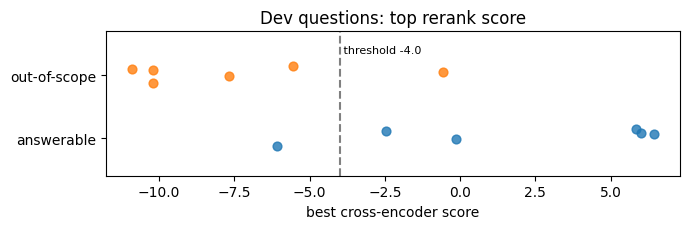

In [ ]:
import matplotlib.pyplot as plt

def top_score(q): return max(e["score"] for e in retrieve(q))
dev_scores = pd.DataFrame([dict(id=t["id"], type=t["type"], question=t["question"], top_score=round(top_score(t["question"]), 2))
                           for t in DEV_SET])
display(dev_scores)

grid = np.round(np.arange(-12, 8.01, 0.25), 2)
ans_s = dev_scores[dev_scores.type != "oos"].top_score.values
oos_s = dev_scores[dev_scores.type == "oos"].top_score.values
calibration = pd.DataFrame([dict(threshold=th, answerable_kept=(ans_s >= th).mean(), oos_blocked=(oos_s < th).mean())
                            for th in grid])
calibration["balanced_accuracy"] = (calibration.answerable_kept + calibration.oos_blocked) / 2
best = calibration.balanced_accuracy.max()
opt = calibration[calibration.balanced_accuracy == best].threshold.tolist()
runs, cur = [], [opt[0]]
for a, b in zip(opt, opt[1:]):
    if round(b - a, 2) <= 0.25:
        cur.append(b)
    else:
        runs.append(cur); cur = [b]
runs.append(cur)
widest = max(runs, key=len)
ABSTAIN_THRESHOLD = round(float((widest[0] + widest[-1]) / 2), 2)
print(f"Best balanced accuracy on dev: {best:.3f} for thresholds {widest[0]} to {widest[-1]} "
      f"-> ABSTAIN_THRESHOLD = {ABSTAIN_THRESHOLD}")
print(f"Dev answerable: lowest top score {ans_s.min():.2f} | dev out-of-scope: highest top score {oos_s.max():.2f}"
      + ("  (overlap: near-domain questions are left to the model's refusal)" if ans_s.min() <= oos_s.max() else ""))

fig, ax = plt.subplots(figsize=(7, 2.4))
for y, (lab, vals) in enumerate([("answerable", ans_s), ("out-of-scope", oos_s)]):
    ax.scatter(vals, y + np.random.default_rng(SEED).uniform(-0.15, 0.15, len(vals)), s=40, alpha=0.8, label=lab)
ax.axvline(ABSTAIN_THRESHOLD, ls="--", c="grey"); ax.text(ABSTAIN_THRESHOLD, 1.35, f" threshold {ABSTAIN_THRESHOLD}", fontsize=8)
ax.set_yticks([0, 1]); ax.set_yticklabels(["answerable", "out-of-scope"]); ax.set_ylim(-0.6, 1.7)
ax.set_xlabel("best cross-encoder score"); ax.set_title("Dev questions: top rerank score")
plt.tight_layout(); plt.savefig(f"{WORK_DIR}/threshold_calibration.png", dpi=150); plt.show()

### 9b. Retrieval ablation (test set, answerable questions; retrieval only, no LLM)

In [ ]:
ANSWERABLE = [t for t in TEST_SET if t["type"] != "oos"]

def page_metrics(t, pages):
    exp, need_all = t["expected_pages"], t["type"] == "multi"
    hit = all(p in pages for p in exp) if need_all else any(p in pages for p in exp)
    rr = next((1 / (i + 1) for i, p in enumerate(pages) if p in exp), 0.0)
    return dict(hit=hit, rr=rr, top1=bool(pages) and pages[0] in exp)

MODE_LABELS = {"dense": "Dense only (Qdrant)", "bm25": "BM25 only", "rrf": "Hybrid: dense + BM25 (RRF)",
               "rerank": "Hybrid + cross-encoder rerank", "full": "+ sub-questions + page cap (final system)"}
rows, per_q = [], []
for mode, label in MODE_LABELS.items():
    ms = []
    for t in ANSWERABLE:
        m = page_metrics(t, [e["page"] for e in retrieve(t["question"], mode=mode)])
        ms.append(m); per_q.append(dict(mode=mode, id=t["id"], **m))
    multi = [m for t, m in zip(ANSWERABLE, ms) if t["type"] == "multi"]
    rows.append({"retrieval": label, "Hit@1": np.mean([m["top1"] for m in ms]),
                 f"Hit@{FINAL_N}": np.mean([m["hit"] for m in ms]), "MRR": np.mean([m["rr"] for m in ms]),
                 f"Hit@{FINAL_N} multi-section (all pages)": np.mean([m["hit"] for m in multi])})
ablation = pd.DataFrame(rows).set_index("retrieval").round(3)
display(ablation)
misses = pd.DataFrame(per_q).query("mode == 'full' and not hit")
print("Answerable questions the final retrieval misses:", misses.id.tolist() or "none")

,Hit@1,Hit@4,MRR,Hit@4 multi-section (all pages)
retrieval,,,,
Dense only (Qdrant),0.76,0.92,0.857,0.6
BM25 only,1.00,1.00,1.000,1.0
Hybrid: dense + BM25 (RRF),0.84,0.92,0.913,0.6
Hybrid + cross-encoder rerank,0.96,0.96,0.980,0.8
+ sub-questions + page cap (final system),0.92,1.00,0.960,1.0


Answerable questions the final retrieval misses: none


### 9c. Trade-offs: how many chunks (k) and how big a chunk
**k sweep:** the final system with k = 1 to 8 evidence chunks. More chunks raise the chance that the evidence is present, but cost prompt length and give a 3B model more to get distracted by.

**Chunk-size sweep:** the guide re-chunked at three sizes, each re-embedded and searched in memory with the same hybrid + rerank pipeline (Qdrant holds only the production index).

,Hit@k,Hit@k multi-section,MRR,evidence tokens (approx.)
k,,,,
1,0.72,0.0,0.92,185
2,1.00,1.0,0.96,388
3,1.00,1.0,0.96,601
4,1.00,1.0,0.96,790
5,1.00,1.0,0.96,981
6,1.00,1.0,0.96,1179
7,1.00,1.0,0.96,1391
8,1.00,1.0,0.96,1578


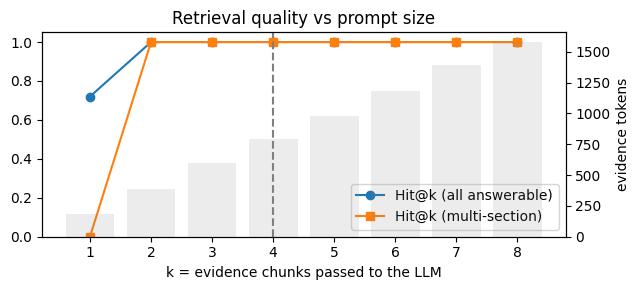

In [ ]:
rows = []
for k in range(1, 9):
    res = [(t, retrieve(t["question"], final_n=k)) for t in ANSWERABLE]
    ms = [page_metrics(t, [e["page"] for e in r]) for t, r in res]
    rows.append({"k": k, "Hit@k": np.mean([m["hit"] for m in ms]),
                 "Hit@k multi-section": np.mean([m["hit"] for t, m in zip(ANSWERABLE, ms) if t["type"] == "multi"]),
                 "MRR": np.mean([m["rr"] for m in ms]),
                 "evidence tokens (approx.)": int(np.mean([sum(len(e["text"].split()) for e in r) * 1.35 for _, r in res]))})
k_sweep = pd.DataFrame(rows).set_index("k").round(3)
display(k_sweep)

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(k_sweep.index, k_sweep["Hit@k"], marker="o", label="Hit@k (all answerable)")
ax.plot(k_sweep.index, k_sweep["Hit@k multi-section"], marker="s", label="Hit@k (multi-section)")
ax.axvline(FINAL_N, ls="--", c="grey"); ax.set_ylim(0, 1.05); ax.set_xlabel("k = evidence chunks passed to the LLM")
ax2 = ax.twinx(); ax2.bar(k_sweep.index, k_sweep["evidence tokens (approx.)"], alpha=0.15, color="grey")
ax2.set_ylabel("evidence tokens"); ax.legend(loc="lower right"); ax.set_title("Retrieval quality vs prompt size")
plt.tight_layout(); plt.savefig(f"{WORK_DIR}/k_sweep.png", dpi=150); plt.show()

In [ ]:
def inmemory_search(cs):
    cs = [c for c in cs if c["retrievable"]]
    vecs = embed_passages([c["embed_text"] for c in cs])
    bm = BM25Okapi([tokenize(c["embed_text"]) for c in cs])
    def search(q, n=FINAL_N):
        qv = embedder.encode(QUERY_PREFIX + q, normalize_embeddings=True)
        ds = vecs @ qv
        d = [(i, float(ds[i])) for i in np.argsort(-ds)[:DENSE_K]]
        bs = bm.get_scores(tokenize(q))
        b = [(i, float(bs[i])) for i in np.argsort(-bs)[:BM25_K] if bs[i] > 0]
        cands = [i for i, _ in rrf([d, b])[:FUSE_K]]
        ce = np.asarray(reranker.predict([(q, cs[i]["embed_text"]) for i in cands]))
        return [cs[cands[j]] for j in np.argsort(-ce)[:n]]
    return search

rows = []
for cw in [120, CHUNK_WORDS, 350]:
    cs = add_unit_refs(build_chunks(segments, cw, OVERLAP_WORDS))
    search = inmemory_search(cs)
    res = [(t, search(t["question"])) for t in ANSWERABLE]
    ms = [page_metrics(t, [c["page"] for c in r]) for t, r in res]
    rows.append({"chunk_words": cw, "n_chunks": len(cs), "median words": int(np.median([len(c["text"].split()) for c in cs])),
                 f"Hit@{FINAL_N}": np.mean([m["hit"] for m in ms]), "MRR": np.mean([m["rr"] for m in ms]),
                 "evidence tokens (approx.)": int(np.mean([sum(len(c["text"].split()) for c in r) * 1.35 for _, r in res]))})
chunk_sweep = pd.DataFrame(rows).set_index("chunk_words").round(3)
display(chunk_sweep)
print(f"Production setting: {CHUNK_WORDS} words. (Same hybrid + rerank pipeline, without sub-questions and page cap.)")

,n_chunks,median words,Hit@4,MRR,evidence tokens (approx.)
chunk_words,,,,,
120,56,87,0.92,1.000,470
220,35,102,0.96,0.980,762
350,30,95,1.00,0.973,1090


Production setting: 220 words. (Same hybrid + rerank pipeline, without sub-questions and page cap.)


### 9d. Full evaluation (test set)
For each question this records the expected source, whether the correct evidence was retrieved, whether the answer is correct, whether the citations point to the expected page(s), which abstention layer fired, numbers not found in the evidence, and the response time.

**Manual review.** The automatic answer check looks for the expected keywords. Read the `answer` column and put any correction in `MANUAL_REVIEW`, e.g. `{"F10": True, "M5": False}`, then re-run the summary cell. Overrides are applied to every model run in 9d and 9e.

In [ ]:
def kw_ok(answer, keywords):
    a = _norm(answer)
    return all(any(_norm(alt) in a for alt in k.split("|")) for k in keywords)

def run_eval(label, items=None, final_n=FINAL_N):
    rows = []
    for t in items or TEST_SET:
        r = rag_answer(t["question"], final_n=final_n)
        got, cited = [e["page"] for e in r["retrieved"]], [c["page"] for c in r["citations"]]
        oos = t["type"] == "oos"
        m = None if oos else page_metrics(t, got)
        c = None if oos else page_metrics(t, cited)
        rows.append(dict(
            model=label, id=t["id"], type=t["type"], question=t["question"], expected_pages=t["expected_pages"],
            expected_section=t["expected_section"], retrieved_pages=got, cited_pages=cited,
            hit_at_k=None if oos else m["hit"], rr=None if oos else m["rr"],
            abstained=r["abstained"], abstain_layer=r["abstain_layer"],
            answer_correct_auto=r["abstained"] if oos else (not r["abstained"] and kw_ok(r["answer"], t["expected_keywords"])),
            citation_correct=(r["abstained"] and not r["citations"]) if oos else (not r["abstained"] and c["hit"]),
            citation_source=r["citation_source"], unknown_ids=len(r["unknown_tags"]),
            ungrounded_numbers=", ".join(r["ungrounded_numbers"]), top_score=round(r["top_score"], 2),
            seconds=r["seconds"], answer=r["answer"], citations=" | ".join(c["label"] for c in r["citations"])))
    return pd.DataFrame(rows)

MODEL_LABEL = "Qwen2.5-3B + LoRA" if isinstance(gen_model, PeftModel) else "Qwen2.5-3B base"
results = run_eval(MODEL_LABEL)
results.to_csv(f"{WORK_DIR}/eval_results.csv", index=False)
print("Model evaluated:", MODEL_LABEL, "| abstention threshold:", ABSTAIN_THRESHOLD)
display(results.drop(columns=["question", "answer", "citations", "expected_section"]))

Model evaluated: Qwen2.5-3B + LoRA | abstention threshold: -4.0


,model,id,type,expected_pages,retrieved_pages,cited_pages,hit_at_k,rr,abstained,abstain_layer,answer_correct_auto,citation_correct,citation_source,unknown_ids,ungrounded_numbers,top_score,seconds
0,Qwen2.5-3B + LoRA,F1,factual,[3],"[3, 16, 3, 1]",[3],True,1.0,False,,True,True,model passage IDs,0,,5.37,3.08
1,Qwen2.5-3B + LoRA,F2,factual,[6],"[6, 12, 15, 11]",[6],True,1.0,False,,True,True,model passage IDs,0,,7.76,3.17
2,Qwen2.5-3B + LoRA,F3,factual,[15],"[15, 15, 13, 13]",[15],True,1.0,False,,True,True,model passage IDs,0,,1.72,2.76
3,Qwen2.5-3B + LoRA,F4,factual,[7],"[7, 6, 13, 4]",[7],True,1.0,False,,True,True,model passage IDs,0,,7.15,2.90
4,Qwen2.5-3B + LoRA,F5,factual,[3],"[3, 16, 3, 15]",[3],True,1.0,False,,True,True,model passage IDs,0,,1.46,3.58
5,Qwen2.5-3B + LoRA,F6,factual,[11],"[7, 11, 12, 14]",[11],True,0.5,False,,True,True,model passage IDs,0,,1.59,3.25
6,Qwen2.5-3B + LoRA,F7,factual,[8],"[8, 11, 13, 6]",[8],True,1.0,False,,True,True,model passage IDs,0,,5.61,3.20
7,Qwen2.5-3B + LoRA,F8,factual,[15],"[15, 13, 13, 15]",[15],True,1.0,False,,True,True,model passage IDs,0,,0.93,5.15
8,Qwen2.5-3B + LoRA,F9,factual,[16],"[16, 6, 1, 12]",[16],True,1.0,False,,True,True,model passage IDs,0,,0.44,2.79
9,Qwen2.5-3B + LoRA,F10,factual,[6],"[6, 12, 13, 13]",[12],True,1.0,False,,True,False,model passage IDs,0,,7.12,2.38


In [ ]:
MANUAL_REVIEW = {}   # e.g. {"F10": True} after reading an answer the keyword check misjudged

def summarise(df):
    d = df.copy()
    d["answer_ok"] = [MANUAL_REVIEW.get(i, a) for i, a in zip(d.id, d.answer_correct_auto)]
    ans, oos = d[d.type != "oos"], d[d.type == "oos"]
    answered = ans[~ans.abstained]
    s = pd.Series({
        f"Retrieval Hit@{FINAL_N} (answerable)": ans.hit_at_k.astype(bool).mean(),
        "Retrieval MRR (answerable)": ans.rr.astype(float).mean(),
        "Answer accuracy (answerable)": ans.answer_ok.mean(),
        "   factual": ans[ans.type == "factual"].answer_ok.mean(),
        "   multi-section": ans[ans.type == "multi"].answer_ok.mean(),
        "Citation accuracy (answerable)": ans.citation_correct.astype(bool).mean(),
        "Abstention success (out-of-scope)": oos.abstained.mean() if len(oos) else np.nan,
        "False-abstention rate (answerable)": ans.abstained.mean(),
        "Abstentions by retrieval gate (count)": int((d.abstain_layer == "retrieval gate").sum()),
        "Abstentions by model (count)": int((d.abstain_layer == "model").sum()),
        "Answers citing via fallback (count)": int(d.citation_source.str.startswith("fallback").sum()),
        "Answers with numbers not in evidence": (answered.ungrounded_numbers != "").mean() if len(answered) else np.nan,
        "Median response time (s)": d.seconds.median(),
        "90th percentile response time (s)": d.seconds.quantile(0.9),
    })
    return s, d

summary, res = summarise(results)
display(summary.round(3).to_frame(MODEL_LABEL))
print("\nFailures to analyse in the report (wrong answer, wrong citation, or a wrong abstention):")
fail = res[~(res.answer_ok & res.citation_correct.astype(bool))]
display(fail[["id", "type", "expected_pages", "retrieved_pages", "cited_pages", "abstain_layer", "answer"]])

,Qwen2.5-3B + LoRA
Retrieval Hit@4 (answerable),1.00
Retrieval MRR (answerable),0.96
Answer accuracy (answerable),0.92
factual,1.00
multi-section,0.60
Citation accuracy (answerable),0.76
Abstention success (out-of-scope),1.00
False-abstention rate (answerable),0.00
Abstentions by retrieval gate (count),5.00
Abstentions by model (count),1.00



Failures to analyse in the report (wrong answer, wrong citation, or a wrong abstention):


,id,type,expected_pages,retrieved_pages,cited_pages,abstain_layer,answer
9,F10,factual,[6],"[6, 12, 13, 13]",[12],,4-6 hours of class per week. [1]
20,M1,multi,"[8, 13]","[13, 8, 6, 13]",[13],,The Bayesian Networks unit is scheduled for 3 weeks. It covers foundations o...
21,M2,multi,"[3, 16]","[3, 16, 3, 15]",[16],,A student should contact the lecturers via email using a specific template. ...
22,M3,multi,"[11, 15]","[11, 12, 15, 4]",[12],,"Assignment 1 involves Looker Studio. During the module, students will build ..."
23,M4,multi,"[13, 15]","[13, 13, 6, 15]",[13],,The weight of Assignment 2 is 20%. The Exploratory Data Analysis unit is sch...
24,M5,multi,"[1, 6]","[1, 6, 16, 3]","[1, 16]",,EDAB6808 is at NQF level 8. Students should work a minimum of 12 hours outsi...


In [ ]:
# Optional: answer quality (not just retrieval) for different k. About 3 extra test runs.
RUN_LLM_K_SWEEP = False
if RUN_LLM_K_SWEEP:
    llm_k = {}
    for k in [2, 4, 6]:
        s, _ = summarise(run_eval(f"k={k}", final_n=k))
        llm_k[f"k={k}"] = s
    llm_k_sweep = pd.DataFrame(llm_k).round(3)
    display(llm_k_sweep)

### 9e. Base vs fine-tuned
Same questions, same retrieval; only the generator changes. `disable_adapter()` switches the LoRA weights off temporarily, so the retrieval rows are identical by construction and any difference in answers, citations or abstentions comes from fine-tuning alone.

In [ ]:
if isinstance(gen_model, PeftModel):
    with gen_model.disable_adapter():
        base_results = run_eval("Qwen2.5-3B base")
    base_results.to_csv(f"{WORK_DIR}/eval_results_base.csv", index=False)
    s_base, d_base = summarise(base_results)
    s_ft, d_ft = summarise(results)
    comparison = pd.DataFrame({"Base (no adapter)": s_base, "Fine-tuned (LoRA)": s_ft})
    comparison["Change"] = comparison["Fine-tuned (LoRA)"] - comparison["Base (no adapter)"]
    comparison = comparison.round(3)
    display(comparison)

    per_q = pd.DataFrame({"id": d_ft.id, "type": d_ft.type,
                          "base_correct": d_base.answer_ok.values, "lora_correct": d_ft.answer_ok.values,
                          "base_cited_ok": d_base.citation_correct.astype(bool).values,
                          "lora_cited_ok": d_ft.citation_correct.astype(bool).values,
                          "base_abstained": d_base.abstained.values, "lora_abstained": d_ft.abstained.values,
                          "base_answer": d_base.answer.str[:120].values, "lora_answer": d_ft.answer.str[:120].values})
    changed = per_q[(per_q.base_correct != per_q.lora_correct) | (per_q.base_cited_ok != per_q.lora_cited_ok)
                    | (per_q.base_abstained != per_q.lora_abstained)]
    print(f"Questions where the adapter changed the outcome: {len(changed)} of {len(per_q)}")
    display(changed)
else:
    comparison = None
    print("No adapter loaded: run section 7b, then re-run 9d and this cell.")

,Base (no adapter),Fine-tuned (LoRA),Change
Retrieval Hit@4 (answerable),1.00,1.00,0.00
Retrieval MRR (answerable),0.96,0.96,0.00
Answer accuracy (answerable),0.88,0.92,0.04
factual,0.90,1.00,0.10
multi-section,0.80,0.60,-0.20
Citation accuracy (answerable),0.80,0.76,-0.04
Abstention success (out-of-scope),1.00,1.00,0.00
False-abstention rate (answerable),0.00,0.00,0.00
Abstentions by retrieval gate (count),5.00,5.00,0.00
Abstentions by model (count),1.00,1.00,0.00


Questions where the adapter changed the outcome: 4 of 31


,id,type,base_correct,lora_correct,base_cited_ok,lora_cited_ok,base_abstained,lora_abstained,base_answer,lora_answer
9,F10,factual,False,True,False,False,False,False,4 hours [1]\n\nI cannot find this in the EDAB 6808 Learner Guide.,4-6 hours of class per week. [1]
11,F12,factual,False,True,True,True,False,False,No,"No, there is no prescribed textbook for this module. [1]"
20,M1,multi,True,False,False,False,False,False,The Bayesian Networks unit is scheduled for 3 weeks. It covers the foundatio...,The Bayesian Networks unit is scheduled for 3 weeks. It covers foundations o...
21,M2,multi,True,True,True,False,False,False,A student should contact the lecturers via email using a specific template. ...,A student should contact the lecturers via email using a specific template. ...


### 9f. RAGAS context metrics
**Reference contexts** are the 7a `evidence` passages (copied verbatim from the guide and checked against their pages), widened to a 50-word window of surrounding guide text. They are printed below for checking.

Two implementations:
1. **RAGAS-style metrics with rapidfuzz** (always run, reported): *context recall* = share of reference passages found in the retrieved chunks; *context precision* = average precision of the ranked retrieved list, where a chunk counts as relevant if it contains a reference passage. "Contains" means `fuzz.partial_ratio ≥ 70`. In a check on real text, fully contained passages scored 100, half-contained about 77 and unrelated text about 45.
2. **The `ragas` package** (`NonLLMContextRecall`, `NonLLMContextPrecisionWithReference`), shown alongside if it imports. Its install has failed in Colab before on a `langchain_community` import; if that happens, report the rapidfuzz numbers and say so.

In [ ]:
from rapidfuzz import fuzz

page_raw = {p["page"]: " ".join(" ".join(l["text"] for l in p["lines"]).split()) for p in clean_pages}

def reference_contexts(t, half_window=25):
    refs = []
    for i, ev in enumerate(t["evidence"]):
        pages = [t["expected_pages"][i]] if t["type"] == "multi" else t["expected_pages"]
        for p in pages:
            words, joined = page_raw[p].split(), page_raw[p].lower()
            pos = joined.find(" ".join(ev.split()).lower())
            if pos >= 0:
                wi = joined[:pos].count(" ")
                refs.append(" ".join(words[max(0, wi - half_window): wi + len(ev.split()) + half_window]))
                break
    return refs

SIM_THRESHOLD = 70
def contains(chunk_text, ref): return fuzz.partial_ratio(ref, chunk_text) >= SIM_THRESHOLD
def context_recall(refs, retrieved): return float(np.mean([any(contains(c, r) for c in retrieved) for r in refs]))
def context_precision(refs, retrieved):
    hits, ap = 0, 0.0
    for k, c in enumerate(retrieved, start=1):
        if any(contains(c, r) for r in refs):
            hits += 1; ap += hits / k
    return ap / hits if hits else 0.0

ctx_rows, ragas_inputs = [], []
for t in ANSWERABLE:
    refs = reference_contexts(t)
    retrieved = [e["text"] for e in retrieve(t["question"])]
    ctx_rows.append(dict(id=t["id"], type=t["type"], n_refs=len(refs), context_recall=context_recall(refs, retrieved),
                         context_precision=context_precision(refs, retrieved)))
    ragas_inputs.append((t["id"], refs, retrieved))
    print(f"{t['id']}: " + " || ".join(r[:100] + "..." for r in refs))

context_metrics = pd.DataFrame(ctx_rows)
display(context_metrics.round(3))
print("Mean (rapidfuzz, RAGAS-style):", context_metrics[["context_recall", "context_precision"]].mean().round(3).to_dict())

TRY_RAGAS_PACKAGE = True
if TRY_RAGAS_PACKAGE:
    try:
        !pip install -q ragas
        import nest_asyncio, asyncio
        nest_asyncio.apply()
        from ragas import SingleTurnSample
        from ragas.metrics import NonLLMContextRecall, NonLLMContextPrecisionWithReference
        rec, prec = NonLLMContextRecall(), NonLLMContextPrecisionWithReference()
        loop = asyncio.get_event_loop()
        out = []
        for qid, refs, retrieved in ragas_inputs:
            s = SingleTurnSample(retrieved_contexts=retrieved, reference_contexts=refs)
            out.append(dict(id=qid, ragas_context_recall=loop.run_until_complete(rec.single_turn_ascore(s)),
                            ragas_context_precision=loop.run_until_complete(prec.single_turn_ascore(s))))
        ragas_df = pd.DataFrame(out)
        context_metrics = context_metrics.merge(ragas_df, on="id")
        display(context_metrics.round(3))
        print("Mean (ragas package):", ragas_df.mean(numeric_only=True).round(3).to_dict())
    except Exception as e:
        print("ragas package not usable in this runtime:", repr(e)[:200])
        print("-> report the rapidfuzz RAGAS-style metrics above and note the package issue.")

F1: and complex systems. Here is all the information that you will need to contact us: LECTURER Lecturer...
F2: and ethical reasoning through the assignments. 4. HOW LEARNING WILL TAKE PLACE This is a 32-credit m...
F3: Assignment 4; TYPE (E.G. WRITTEN/ORAL/PRACTICAL): Notebook + PowerPoint presentation 30 minutes per ...
F4: in business contexts. - Identify key components such as trends, seasonality, and cyclic behavior. Ad...
F5: Trip Office number: FGG 352 Email address: CombrinkHM@UFS.ac.za; OelofseVEO@ufs.ac.za; TripJK@ufs.ac...
F6: will spend substantial time in the Google environment, where they will build competency in data wran...
F7: business environments. Key Topics & Learning Objectives: Foundations of Bayesian Networks: - Underst...
F8: the oral test immediately after the oral, as the assessment of the answers will be based on a rubric...
F9: and a representative in society. It is vital that you carry yourself using: • Conduct, • Integrity •...
F10: spend a minimum of 320 

,id,type,n_refs,context_recall,context_precision
0,F1,factual,1,1.0,0.833
1,F2,factual,1,1.0,1.000
2,F3,factual,1,1.0,1.000
3,F4,factual,1,1.0,1.000
4,F5,factual,1,1.0,1.000
5,F6,factual,1,1.0,0.500
6,F7,factual,1,1.0,1.000
7,F8,factual,1,1.0,1.000
8,F9,factual,1,1.0,1.000
9,F10,factual,1,1.0,1.000


Mean (rapidfuzz, RAGAS-style): {'context_recall': 1.0, 'context_precision': 0.927}
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 466.5/466.5 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 269.4/269.4 kB 27.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 76.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 145.6/145.6 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 573.0/573.0 kB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 106.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 353.2/353.2 kB 32.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 65.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13

### 9g. Save every table for the report

In [ ]:
report_path = f"{WORK_DIR}/rag_evaluation_report.xlsx"
sheets = {
    "summary": summary.round(3).to_frame(MODEL_LABEL),
    "test_results": results,
    "retrieval_ablation": ablation,
    "k_sweep": k_sweep,
    "chunk_size_sweep": chunk_sweep,
    "threshold_dev_scores": dev_scores,
    "threshold_grid": calibration,
    "context_metrics": context_metrics,
    "chunks": pd.DataFrame(chunks)[["chunk_id", "page", "printed_page", "heading", "kind", "retrievable", "unit_refs", "text"]],
}
if globals().get("comparison") is not None:
    sheets["base_vs_lora"] = comparison
if globals().get("llm_k_sweep") is not None:
    sheets["llm_k_sweep"] = llm_k_sweep
with pd.ExcelWriter(report_path) as xw:
    for name, df in sheets.items():
        df.to_excel(xw, sheet_name=name[:31])
print("Saved", report_path, "with sheets:", list(sheets))
print("Figures:", [f for f in os.listdir(WORK_DIR) if f.endswith(".png")])

Saved /content/drive/MyDrive/EDAB6808/rag_store/rag_evaluation_report.xlsx with sheets: ['summary', 'test_results', 'retrieval_ablation', 'k_sweep', 'chunk_size_sweep', 'threshold_dev_scores', 'threshold_grid', 'context_metrics', 'chunks', 'base_vs_lora']
Figures: ['train_loss.png', 'threshold_calibration.png', 'k_sweep.png']


## 10. Gradio chatbot interface
Ask questions and see the answer with numbered citations. The right-hand panel shows the
retrieved evidence: page, section and unit, chunk ID, rerank score, and whether it was cited.
Abstentions show their reason; numbers absent from the evidence are flagged.

Run Sections **1–8** successfully before this cell (including 7a and 7b for the complete
fine-tuned pipeline). You can launch before running the Section 9 evaluation, but complete
Section 9 for the assignment results. Run Section 9a first if you want the calibrated
abstention threshold in this session. Example buttons do not depend on `TEST_SET`.
Gradio 5 needs `type="messages"`; Gradio 6 uses that format automatically. This cell chooses
the appropriate constructor. It uses the standard event loop and Gradio's automatic port
selection. Rerunning this cell closes the preceding interface.

History is displayed between questions; `rag_answer` answers each question independently.
The share link is public and temporary. Keep the Colab runtime connected while using it.


In [ ]:
import asyncio
import uvicorn.server

def run_gradio_server(main, *, debug=None, loop_factory=None):
    with asyncio.Runner(
        debug=debug,
        loop_factory=loop_factory
    ) as runner:
        return runner.run(main)

uvicorn.server.asyncio_run = run_gradio_server

print("Gradio server compatibility fix applied.")

Gradio server compatibility fix applied.


In [ ]:
import threading
import gradio as gr

# Fail early with a useful message if a previous section was skipped or failed.
required_functions = {
    "pg_label": "1", "retrieve": "6", "generate": "7", "rag_answer": "8"
}
missing = [f"{name} (Section {section})"
           for name, section in required_functions.items()
           if not callable(globals().get(name))]
missing += [f"{name} (Section 7)" for name in ("gen_model", "gen_tok")
            if globals().get(name) is None]
if missing:
    raise RuntimeError("Run the required earlier cells successfully before launching: "
                       + ", ".join(missing))

GRADIO_MAJOR = int(gr.__version__.split(".")[0])
if GRADIO_MAJOR not in (5, 6):
    raise RuntimeError("Run Section 0 and restart the session: this notebook supports Gradio 5 and 6.")
print(f"Using Gradio {gr.__version__}")

EVIDENCE_PLACEHOLDER = "_Source evidence appears here after you ask a question._"
chat_lock = threading.Lock()

def evidence_md(r):
    head = []
    if r["abstained"]:
        head.append(f"**Abstained ({r['abstain_layer']})**: {r['reason']}.")
    if r["ungrounded_numbers"]:
        head.append(f"**Check:** these numbers are not in the evidence: {', '.join(r['ungrounded_numbers'])}")
    if r["citation_source"].startswith("fallback"):
        head.append("_The model gave no passage ID, so the top-ranked passage is shown as the source._")
    cited = {c["chunk_id"]: c["n"] for c in r["citations"]}
    blocks = []
    for e in r["retrieved"]:
        tag = f"**cited [{cited[e['chunk_id']]}]**" if e["chunk_id"] in cited else "not cited"
        excerpt = e["text"][:450].replace("\n", "\n> ") + ("…" if len(e["text"]) > 450 else "")
        blocks.append(f"**{pg_label(e['page'])} · {e['heading']}**  \n"
                      f"`{e['chunk_id']}` · rerank {e['score']:.2f} · {tag}\n\n> {excerpt}")
    body = "\n\n---\n\n".join(blocks) or "_No evidence retrieved._"
    return ("\n\n".join(head) + ("\n\n---\n\n" if head else "")
            + body + f"\n\n*Response time: {r['seconds']} s*")

def chat_fn(message, history):
    history = history or []
    if not message or not message.strip():
        return "", history, gr.update()
    with chat_lock:
        r = rag_answer(message.strip())
    reply = r["answer"]
    if r["citations"]:
        reply += "\n\n**Sources**\n" + "\n".join(f"- {c['label']}" for c in r["citations"])
    history = history + [{"role": "user", "content": message.strip()},
                         {"role": "assistant", "content": reply}]
    return "", history, evidence_md(r)

# Interface examples are independent of evaluation variables.
EXAMPLES = [
    "How many notional learning hours are required for the module?",
    "What percentage of the module mark does Assignment 5 contribute?",
    "What are the components of a Bayesian network?",
    "How many weeks is the Bayesian Networks unit scheduled for, and what topic areas does it cover?",
    "What is the weight of Assignment 2, and how many weeks is the Exploratory Data Analysis unit scheduled for?",
    "What is the minimum pass mark for EDAB6808?",
]

old_demo = globals().get("demo")
if old_demo is not None:
    old_demo.close()

with gr.Blocks(title="EDAB 6808 Learner Guide Assistant") as demo:
    gr.Markdown("# EDAB 6808 Learner Guide Assistant\n"
                "Answers come **only** from the learner guide, with numbered sources. "
                "Questions the guide does not cover are refused.")
    with gr.Row():
        with gr.Column(scale=3):
            chatbot_options = dict(height=480, label="Conversation")
            if GRADIO_MAJOR == 5:
                chatbot_options["type"] = "messages"
            chatbot = gr.Chatbot(**chatbot_options)
            box = gr.Textbox(placeholder="Ask a question about the learner guide and press Enter…",
                             show_label=False)
            with gr.Row():
                ask = gr.Button("Ask", variant="primary")
                clear = gr.Button("Clear")
            gr.Examples(EXAMPLES, inputs=box, label="Example questions")
        with gr.Column(scale=2):
            src = gr.Markdown(EVIDENCE_PLACEHOLDER)
    box.submit(chat_fn, [box, chatbot], [box, chatbot, src],
               concurrency_limit=1, concurrency_id="rag_chat")
    ask.click(chat_fn, [box, chatbot], [box, chatbot, src],
              concurrency_limit=1, concurrency_id="rag_chat")
    clear.click(lambda: ([], "", EVIDENCE_PLACEHOLDER), None,
                [chatbot, box, src], queue=False)

demo.queue(default_concurrency_limit=1)
demo.launch(share=True, inline=True, debug=False,
            prevent_thread_lock=True, show_error=True)


Using Gradio 6.30.0
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f00c339539ebef02c1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Chatbot Evaluation

We tested the chatbot using **31 questions**: 20 straightforward questions, five requiring information from different parts of the guide, and six outside the guide’s scope.

The evaluation checked whether the chatbot retrieved the required source pages, answered correctly, provided appropriate citations and refused unsupported questions.

### Recorded Results

| Measure | Result |
|---|---:|
| Required source pages retrieved | 25/25 answerable questions (100%) |
| Answer accuracy on answerable questions | 92% |
| Citation accuracy | 76% |
| Out-of-scope questions correctly refused | 6/6 (100%) |
| Answerable questions incorrectly refused | 0 |
| Median response time | 3.4 seconds |

### Interpretation

The chatbot generally found useful information and answered straightforward questions well. Its main weakness was answering and citing questions that required several passages.

LoRA fine-tuning increased the reported answer accuracy from **88% to 92%**, but performance on questions requiring multiple sources declined. Future training should include more examples combining information from different passages.

These results come from a small test set. Answer accuracy used an automatic keyword check, supplemented by manual inspection. Finding the correct page or displaying a citation does not, by itself, prove that an answer is fully supported.